In [1]:

import pandas as pd
from pathlib import Path

# Load the processed Oracle's Elixir dataset
PROJECT_ROOT = Path.cwd().parent

elixir_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "worlds_swiss_onward.csv"
)

elixir_df = pd.read_csv(elixir_path)

# Keep only the two team summary rows per game
elixir_teams = elixir_df[
    elixir_df["position"] == "team"
].copy()

# Select the columns useful for matching
match_columns = [
    "gameid",
    "date",
    "game",
    "teamname",
    "side",
    "result",
    "gamelength"
]

elixir_matches = elixir_teams[match_columns].copy()

# Convert date to datetime
elixir_matches["date"] = pd.to_datetime(
    elixir_matches["date"]
)

# Sort chronologically
elixir_matches = elixir_matches.sort_values(
    ["date", "gameid", "side"]
)

print("Unique Oracle's Elixir games:",
      elixir_matches["gameid"].nunique())

print("Team rows:", len(elixir_matches))

display(elixir_matches.head(20))


Unique Oracle's Elixir games: 72
Team rows: 144


,gameid,date,game,teamname,side,result,gamelength
10,LOLTMNT02_482269,2026-10-23 17:21:18,1,Invictus Gaming,Blue,0,1561
11,LOLTMNT02_482269,2026-10-23 17:21:18,1,Gen.G,Red,1,1561
22,LOLTMNT02_483314,2026-10-23 18:23:03,1,Top Esports,Blue,0,1431
23,LOLTMNT02_483314,2026-10-23 18:23:03,1,Hanwha Life Esports,Red,1,1431
34,LOLTMNT02_483342,2026-10-23 19:12:48,1,Movistar KOI,Blue,1,2321
35,LOLTMNT02_483342,2026-10-23 19:12:48,1,Bilibili Gaming,Red,0,2321
46,LOLTMNT02_482292,2026-10-23 20:16:06,1,Karmine Corp,Blue,1,1996
47,LOLTMNT02_482292,2026-10-23 20:16:06,1,Anyone's Legend,Red,0,1996
58,LOLTMNT02_482304,2026-10-23 21:16:28,1,Dplus Kia,Blue,1,1958
59,LOLTMNT02_482304,2026-10-23 21:16:28,1,G2 Esports,Red,0,1958


In [2]:

# Create separate Blue and Red team tables
blue_teams = (
    elixir_matches[elixir_matches["side"] == "Blue"]
    .drop(columns=["side"])
    .rename(columns={
        "teamname": "blue_team",
        "result": "blue_result"
    })
)

red_teams = (
    elixir_matches[elixir_matches["side"] == "Red"]
    .drop(columns=["side", "date", "game", "gamelength"])
    .rename(columns={
        "teamname": "red_team",
        "result": "red_result"
    })
)

# Merge Blue and Red teams using Oracle's Elixir gameid
elixir_game_table = blue_teams.merge(
    red_teams,
    on="gameid",
    how="inner"
)

elixir_game_table = elixir_game_table.sort_values(
    ["date", "game"]
).reset_index(drop=True)

display(elixir_game_table.head(20))


,gameid,date,game,blue_team,blue_result,gamelength,red_team,red_result
0,LOLTMNT02_482269,2026-10-23 17:21:18,1,Invictus Gaming,0,1561,Gen.G,1
1,LOLTMNT02_483314,2026-10-23 18:23:03,1,Top Esports,0,1431,Hanwha Life Esports,1
2,LOLTMNT02_483342,2026-10-23 19:12:48,1,Movistar KOI,1,2321,Bilibili Gaming,0
3,LOLTMNT02_482292,2026-10-23 20:16:06,1,Karmine Corp,1,1996,Anyone's Legend,0
4,LOLTMNT02_482304,2026-10-23 21:16:28,1,Dplus Kia,1,1958,G2 Esports,0
5,LOLTMNT02_482313,2026-10-23 22:17:20,1,Team Liquid,0,2252,CTBC Flying Oyster,1
6,LOLTMNT02_482325,2026-10-23 23:21:10,1,LØS,0,1466,T1,1
7,LOLTMNT02_482335,2026-10-24 00:11:57,1,LYON,1,1609,Team Secret Whales,0
8,LOLTMNT02_482539,2026-10-24 17:11:10,1,Top Esports,1,1818,Anyone's Legend,0
9,LOLTMNT02_482559,2026-10-24 18:08:21,1,Movistar KOI,1,1988,CTBC Flying Oyster,0


In [3]:

golgg_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "worlds_objective_events.csv"
)

golgg_df = pd.read_csv(golgg_path)

# One record per Gol.gg game
golgg_games = (
    golgg_df[
        ["game_id", "team", "result"]
    ]
    .drop_duplicates()
    .sort_values(["game_id", "team"])
)

print("Unique Gol.gg games:",
      golgg_games["game_id"].nunique())

display(golgg_games.head(20))


Unique Gol.gg games: 72


,game_id,team,result
0,83638,Gen.G,WIN
1,83638,Invictus Gaming,LOSS
8,83639,CTBC Flying Oyster,WIN
12,83639,Team Liquid,LOSS
18,83640,Anyone s Legend,LOSS
21,83640,Karmine Corp,WIN
29,83641,Dplus KIA,WIN
28,83641,G2 Esports,LOSS
37,83642,Hanwha Life Esports,WIN
40,83642,Top Esports,LOSS


In [4]:
# normalize team names
import re

def normalize_team(team):
    """Standardize team names across the two data sources."""

    name = str(team).strip().casefold()

    # Known naming differences between sources
    aliases = {
        "løs": "los",
        "los grandes": "los"
    }

    if name in aliases:
        return aliases[name]

    # Remove punctuation and standardize spacing
    name = re.sub(r"[^a-z0-9]+", " ", name)
    return " ".join(name.split())


# Check the normalized names
for name in sorted(
    set(elixir_game_table["blue_team"])
    | set(elixir_game_table["red_team"])
    | set(golgg_games["team"])
):
    print(f"{name:25} -> {normalize_team(name)}")


Anyone s Legend           -> anyone s legend
Anyone's Legend           -> anyone s legend
Bilibili Gaming           -> bilibili gaming
CTBC Flying Oyster        -> ctbc flying oyster
Dplus KIA                 -> dplus kia
Dplus Kia                 -> dplus kia
G2 Esports                -> g2 esports
Gen.G                     -> gen g
Hanwha Life Esports       -> hanwha life esports
Invictus Gaming           -> invictus gaming
Karmine Corp              -> karmine corp
LYON                      -> lyon
Los Grandes               -> los
LØS                       -> los
Movistar KOI              -> movistar koi
T1                        -> t1
Team Liquid               -> team liquid
Team Secret Whales        -> team secret whales
Top Esports               -> top esports


In [5]:
# add winning team

elixir_game_table["winner"] = elixir_game_table.apply(
    lambda row: (
        row["blue_team"]
        if row["blue_result"] == 1
        else row["red_team"]
    ),
    axis=1
)

display(
    elixir_game_table[
        ["gameid", "date", "blue_team", "red_team", "winner"]
    ].head(10)
)


,gameid,date,blue_team,red_team,winner
0,LOLTMNT02_482269,2026-10-23 17:21:18,Invictus Gaming,Gen.G,Gen.G
1,LOLTMNT02_483314,2026-10-23 18:23:03,Top Esports,Hanwha Life Esports,Hanwha Life Esports
2,LOLTMNT02_483342,2026-10-23 19:12:48,Movistar KOI,Bilibili Gaming,Movistar KOI
3,LOLTMNT02_482292,2026-10-23 20:16:06,Karmine Corp,Anyone's Legend,Karmine Corp
4,LOLTMNT02_482304,2026-10-23 21:16:28,Dplus Kia,G2 Esports,Dplus Kia
5,LOLTMNT02_482313,2026-10-23 22:17:20,Team Liquid,CTBC Flying Oyster,CTBC Flying Oyster
6,LOLTMNT02_482325,2026-10-23 23:21:10,LØS,T1,T1
7,LOLTMNT02_482335,2026-10-24 00:11:57,LYON,Team Secret Whales,LYON
8,LOLTMNT02_482539,2026-10-24 17:11:10,Top Esports,Anyone's Legend,Top Esports
9,LOLTMNT02_482559,2026-10-24 18:08:21,Movistar KOI,CTBC Flying Oyster,Movistar KOI


In [6]:

def create_match_key(team1, team2, winner):
    teams = sorted([
        normalize_team(team1),
        normalize_team(team2)
    ])

    return (
        teams[0],
        teams[1],
        normalize_team(winner)
    )


elixir_game_table["match_key"] = elixir_game_table.apply(
    lambda row: create_match_key(
        row["blue_team"],
        row["red_team"],
        row["winner"]
    ),
    axis=1
)

# Check for duplicate matching keys
duplicate_keys = elixir_game_table[
    elixir_game_table["match_key"].duplicated(keep=False)
].sort_values("match_key")

print("Total Oracle games:", len(elixir_game_table))
print("Unique matching keys:", elixir_game_table["match_key"].nunique())
print("Duplicate matching keys:", len(duplicate_keys))

display(duplicate_keys)


Total Oracle games: 72
Unique matching keys: 45
Duplicate matching keys: 45


,gameid,date,game,blue_team,blue_result,gamelength,red_team,red_result,winner,match_key
28,LOLTMNT02_483885,2026-10-26 21:54:37,2,Team Liquid,1,2849,Anyone's Legend,0,Team Liquid,"(anyone s legend, team liquid, team liquid)"
27,LOLTMNT02_482911,2026-10-26 21:01:27,1,Anyone's Legend,0,1993,Team Liquid,1,Team Liquid,"(anyone s legend, team liquid, team liquid)"
59,LOLTMNT02_488087,2026-11-05 23:07:23,2,Dplus Kia,0,1931,Bilibili Gaming,1,Bilibili Gaming,"(bilibili gaming, dplus kia, bilibili gaming)"
58,LOLTMNT02_487095,2026-11-05 22:13:02,1,Bilibili Gaming,1,2001,Dplus Kia,0,Bilibili Gaming,"(bilibili gaming, dplus kia, bilibili gaming)"
60,LOLTMNT02_488090,2026-11-06 00:00:31,3,Dplus Kia,0,1956,Bilibili Gaming,1,Bilibili Gaming,"(bilibili gaming, dplus kia, bilibili gaming)"
49,LOLTMNT02_486564,2026-10-31 22:02:48,1,Bilibili Gaming,1,2511,Hanwha Life Esports,0,Bilibili Gaming,"(bilibili gaming, hanwha life esports, bilibil..."
50,LOLTMNT02_486571,2026-10-31 23:05:06,2,Bilibili Gaming,1,1964,Hanwha Life Esports,0,Bilibili Gaming,"(bilibili gaming, hanwha life esports, bilibil..."
70,LOLTMNT02_488296,2026-11-08 23:57:57,3,Bilibili Gaming,1,2218,T1,0,Bilibili Gaming,"(bilibili gaming, t1, bilibili gaming)"
71,LOLTMNT02_488304,2026-11-09 00:56:00,4,T1,0,2267,Bilibili Gaming,1,Bilibili Gaming,"(bilibili gaming, t1, bilibili gaming)"
68,LOLTMNT02_488293,2026-11-08 22:14:09,1,Bilibili Gaming,1,1825,T1,0,Bilibili Gaming,"(bilibili gaming, t1, bilibili gaming)"


In [7]:

golgg_game_records = []

for game_id, group in golgg_games.groupby("game_id"):

    teams = group["team"].dropna().unique()

    winners = group.loc[
        group["result"] == "WIN",
        "team"
    ].dropna().unique()

    if len(teams) != 2 or len(winners) != 1:
        print(f"Check game {game_id}")
        continue

    golgg_game_records.append({
        "golgg_game_id": game_id,
        "golgg_team_1": teams[0],
        "golgg_team_2": teams[1],
        "golgg_winner": winners[0],
        "match_key": create_match_key(
            teams[0],
            teams[1],
            winners[0]
        )
    })

golgg_game_table = pd.DataFrame(golgg_game_records)

print("Gol.gg games ready:", len(golgg_game_table))
print(
    "Unique Gol.gg matching keys:",
    golgg_game_table["match_key"].nunique()
)

display(golgg_game_table.head(15))


Check game 83651
Check game 83670
Check game 83674
Check game 83687
Gol.gg games ready: 68
Unique Gol.gg matching keys: 44


,golgg_game_id,golgg_team_1,golgg_team_2,golgg_winner,match_key
0,83638,Gen.G,Invictus Gaming,Gen.G,"(gen g, invictus gaming, gen g)"
1,83639,CTBC Flying Oyster,Team Liquid,CTBC Flying Oyster,"(ctbc flying oyster, team liquid, ctbc flying ..."
2,83640,Anyone s Legend,Karmine Corp,Karmine Corp,"(anyone s legend, karmine corp, karmine corp)"
3,83641,Dplus KIA,G2 Esports,Dplus KIA,"(dplus kia, g2 esports, dplus kia)"
4,83642,Hanwha Life Esports,Top Esports,Hanwha Life Esports,"(hanwha life esports, top esports, hanwha life..."
5,83643,Los Grandes,T1,T1,"(los, t1, t1)"
6,83644,LYON,Team Secret Whales,LYON,"(lyon, team secret whales, lyon)"
7,83645,Bilibili Gaming,Movistar KOI,Movistar KOI,"(bilibili gaming, movistar koi, movistar koi)"
8,83646,Anyone s Legend,Top Esports,Top Esports,"(anyone s legend, top esports, top esports)"
9,83647,CTBC Flying Oyster,Movistar KOI,Movistar KOI,"(ctbc flying oyster, movistar koi, movistar koi)"


In [8]:
# Display every Oracle game belonging to a duplicated matching key
duplicate_keys = elixir_game_table[
    elixir_game_table["match_key"].duplicated(keep=False)
].sort_values(
    ["match_key", "date"]
)

display(
    duplicate_keys[
        [
            "gameid",
            "date",
            "game",
            "blue_team",
            "red_team",
            "winner",
            "gamelength",
            "match_key"
        ]
    ]
)

,gameid,date,game,blue_team,red_team,winner,gamelength,match_key
27,LOLTMNT02_482911,2026-10-26 21:01:27,1,Anyone's Legend,Team Liquid,Team Liquid,1993,"(anyone s legend, team liquid, team liquid)"
28,LOLTMNT02_483885,2026-10-26 21:54:37,2,Team Liquid,Anyone's Legend,Team Liquid,2849,"(anyone s legend, team liquid, team liquid)"
58,LOLTMNT02_487095,2026-11-05 22:13:02,1,Bilibili Gaming,Dplus Kia,Bilibili Gaming,2001,"(bilibili gaming, dplus kia, bilibili gaming)"
59,LOLTMNT02_488087,2026-11-05 23:07:23,2,Dplus Kia,Bilibili Gaming,Bilibili Gaming,1931,"(bilibili gaming, dplus kia, bilibili gaming)"
60,LOLTMNT02_488090,2026-11-06 00:00:31,3,Dplus Kia,Bilibili Gaming,Bilibili Gaming,1956,"(bilibili gaming, dplus kia, bilibili gaming)"
49,LOLTMNT02_486564,2026-10-31 22:02:48,1,Bilibili Gaming,Hanwha Life Esports,Bilibili Gaming,2511,"(bilibili gaming, hanwha life esports, bilibil..."
50,LOLTMNT02_486571,2026-10-31 23:05:06,2,Bilibili Gaming,Hanwha Life Esports,Bilibili Gaming,1964,"(bilibili gaming, hanwha life esports, bilibil..."
68,LOLTMNT02_488293,2026-11-08 22:14:09,1,Bilibili Gaming,T1,Bilibili Gaming,1825,"(bilibili gaming, t1, bilibili gaming)"
70,LOLTMNT02_488296,2026-11-08 23:57:57,3,Bilibili Gaming,T1,Bilibili Gaming,2218,"(bilibili gaming, t1, bilibili gaming)"
71,LOLTMNT02_488304,2026-11-09 00:56:00,4,T1,Bilibili Gaming,Bilibili Gaming,2267,"(bilibili gaming, t1, bilibili gaming)"


In [14]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

from bs4 import BeautifulSoup
import pandas as pd
import re
import time

# Start Chrome
options = webdriver.ChromeOptions()
driver = webdriver.Chrome(options=options)

print("Chrome browser started successfully.")

Chrome browser started successfully.


In [15]:
#new method take game length, date, and team sides as our matching key


GAME_ID = 83638

url = f"https://gol.gg/game/stats/{GAME_ID}/page-game/"

driver.get(url)

WebDriverWait(driver, 20).until(
    EC.presence_of_element_located((By.TAG_NAME, "body"))
)

soup = BeautifulSoup(driver.page_source, "html.parser")

# Extract the visible page text
page_text = soup.get_text(" ", strip=True)

# Extract the game date
date_match = re.search(
    r"\b\d{4}-\d{2}-\d{2}\b",
    page_text
)

game_date = date_match.group() if date_match else None

# Extract game duration
duration_match = re.search(
    r"Game Time\s*(\d{1,2}:\d{2})",
    page_text,
    re.IGNORECASE
)

game_duration = (
    duration_match.group(1)
    if duration_match
    else None
)

# Convert duration into seconds
if game_duration:
    minutes, seconds = map(
        int,
        game_duration.split(":")
    )
    gamelength_seconds = minutes * 60 + seconds
else:
    gamelength_seconds = None

# Extract teams using the selectors we already tested
blue_element = soup.select_one(".blue-line-header")
red_element = soup.select_one(".red-line-header")

blue_team = (
    blue_element.find("a").get_text(strip=True)
    if blue_element and blue_element.find("a")
    else None
)

red_team = (
    red_element.find("a").get_text(strip=True)
    if red_element and red_element.find("a")
    else None
)

# Display extracted metadata
game_metadata = pd.DataFrame([{
    "golgg_game_id": GAME_ID,
    "date": game_date,
    "game_duration": game_duration,
    "gamelength_seconds": gamelength_seconds,
    "blue_team": blue_team,
    "red_team": red_team
}])

display(game_metadata)


,golgg_game_id,date,game_duration,gamelength_seconds,blue_team,red_team
0,83638,2026-10-23,26:01,1561,Invictus Gaming,Gen.G


In [16]:
#new scraper
def scrape_golgg_game(game_id, driver):
    """
    Scrape game metadata and timeline events from Gol.gg.
    Returns a dictionary containing metadata and an events DataFrame.
    """

    url = f"https://gol.gg/game/stats/{game_id}/page-game/"

    driver.get(url)

    WebDriverWait(driver, 20).until(
        EC.presence_of_element_located((By.TAG_NAME, "body"))
    )

    soup = BeautifulSoup(driver.page_source, "html.parser")
    page_text = soup.get_text(" ", strip=True)

    # --------------------------------
    # 1. Extract date
    # --------------------------------

    date_match = re.search(
        r"\b\d{4}-\d{2}-\d{2}\b",
        page_text
    )

    game_date = date_match.group() if date_match else None

    # --------------------------------
    # 2. Extract game duration
    # --------------------------------

    duration_match = re.search(
        r"Game Time\s*(\d{1,2}:\d{2})",
        page_text,
        re.IGNORECASE
    )

    game_duration = (
        duration_match.group(1)
        if duration_match
        else None
    )

    if game_duration:
        minutes, seconds = map(int, game_duration.split(":"))
        gamelength_seconds = minutes * 60 + seconds
    else:
        gamelength_seconds = None

    # --------------------------------
    # 3. Extract teams and results
    # --------------------------------

    team_mapping = {}

    for side, css_class in [
        ("Blue", "blue-line-header"),
        ("Red", "red-line-header")
    ]:
        element = soup.select_one(f".{css_class}")

        if element and element.find("a"):
            team_name = element.find("a").get_text(strip=True)
            result_text = element.get_text(" ", strip=True)

            result = (
                "WIN" if "WIN" in result_text
                else "LOSS" if "LOSS" in result_text
                else None
            )

            team_mapping[side] = {
                "team": team_name,
                "result": result
            }

    # --------------------------------
    # 4. Extract timeline events
    # --------------------------------

    events = []

    timeline_elements = soup.select(
        "span.red_action, span.blue_action"
    )

    for element in timeline_elements:

        side = (
            "Blue"
            if "blue_action" in element.get("class", [])
            else "Red"
        )

        team_info = team_mapping.get(side, {})

        text = element.get_text(" ", strip=True)

        time_match = re.search(
            r"\b\d{1,2}:\d{2}\b",
            text
        )

        event_time = time_match.group() if time_match else None

        image = element.find("img")
        event_name = image.get("alt") if image else None

        if event_time:
            minutes, seconds = map(int, event_time.split(":"))
            time_seconds = minutes * 60 + seconds
        else:
            time_seconds = None

        events.append({
            "game_id": game_id,
            "time": event_time,
            "time_seconds": time_seconds,
            "event": event_name,
            "side": side,
            "team": team_info.get("team"),
            "result": team_info.get("result")
        })

    events_df = pd.DataFrame(events)

    # --------------------------------
    # 5. Create game metadata
    # --------------------------------

    metadata = {
        "golgg_game_id": game_id,
        "date": game_date,
        "game_duration": game_duration,
        "gamelength_seconds": gamelength_seconds,
        "blue_team": team_mapping.get("Blue", {}).get("team"),
        "red_team": team_mapping.get("Red", {}).get("team")
    }

    return {
        "metadata": metadata,
        "events": events_df
    }


In [17]:
#test on new function

test_result = scrape_golgg_game(83638, driver)

test_metadata_df = pd.DataFrame([
    test_result["metadata"]
])

display(test_metadata_df)
display(test_result["events"])

,golgg_game_id,date,game_duration,gamelength_seconds,blue_team,red_team
0,83638,2026-10-23,26:01,1561,Invictus Gaming,Gen.G


,game_id,time,time_seconds,event,side,team,result
0,83638,6:14,374,Infernal Drake,Red,Gen.G,WIN
1,83638,6:15,375,First blood,Blue,Invictus Gaming,LOSS
2,83638,12:10,730,Ocean Drake,Red,Gen.G,WIN
3,83638,14:55,895,First Tower,Blue,Invictus Gaming,LOSS
4,83638,15:20,920,Rift Herald,Blue,Invictus Gaming,LOSS
5,83638,17:32,1052,Cloud Drake,Red,Gen.G,WIN
6,83638,22:50,1370,Cloud Drake,Red,Gen.G,WIN
7,83638,23:38,1418,Nashor,Red,Gen.G,WIN


In [18]:
#meta data only scraper


def scrape_golgg_metadata(game_id, driver):
    """
    Extract date, duration, and team names for one Gol.gg game.
    Returns one dictionary containing game metadata.
    """

    url = f"https://gol.gg/game/stats/{game_id}/page-game/"

    driver.get(url)

    WebDriverWait(driver, 20).until(
        EC.presence_of_element_located((By.TAG_NAME, "body"))
    )

    soup = BeautifulSoup(driver.page_source, "html.parser")
    page_text = soup.get_text(" ", strip=True)

    # Extract date
    date_match = re.search(
        r"\b\d{4}-\d{2}-\d{2}\b",
        page_text
    )

    game_date = date_match.group() if date_match else None

    # Extract game duration
    duration_match = re.search(
        r"Game Time\s*(\d{1,2}:\d{2})",
        page_text,
        re.IGNORECASE
    )

    game_duration = (
        duration_match.group(1)
        if duration_match
        else None
    )

    # Convert duration to seconds
    if game_duration:
        minutes, seconds = map(int, game_duration.split(":"))
        gamelength_seconds = minutes * 60 + seconds
    else:
        gamelength_seconds = None

    # Extract team names
    blue_element = soup.select_one(".blue-line-header")
    red_element = soup.select_one(".red-line-header")

    blue_team = (
        blue_element.find("a").get_text(strip=True)
        if blue_element and blue_element.find("a")
        else None
    )

    red_team = (
        red_element.find("a").get_text(strip=True)
        if red_element and red_element.find("a")
        else None
    )

    return {
        "golgg_game_id": game_id,
        "date": game_date,
        "game_duration": game_duration,
        "gamelength_seconds": gamelength_seconds,
        "blue_team": blue_team,
        "red_team": red_team
    }


In [19]:
#scrape all 72 games
# Load the existing event dataset
EVENTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "worlds_objective_events.csv"
)

golgg_df = pd.read_csv(EVENTS_PATH)

# Get the 72 unique game IDs
game_ids = sorted(
    golgg_df["game_id"].dropna().astype(int).unique()
)

print("Games to process:", len(game_ids))

# Store metadata
all_metadata = []
failed_metadata_games = []

for i, game_id in enumerate(game_ids, start=1):

    print(f"[{i}/{len(game_ids)}] Scraping game {game_id}...")

    try:
        metadata = scrape_golgg_metadata(
            game_id,
            driver
        )

        all_metadata.append(metadata)

        print(
            f"  {metadata['blue_team']} vs "
            f"{metadata['red_team']} | "
            f"{metadata['game_duration']}"
        )

    except Exception as error:
        print(f"  Failed: {error}")
        failed_metadata_games.append(game_id)

        page_text = driver.page_source.lower()

        if any(term in page_text for term in [
            "403 forbidden",
            "access denied",
            "request blocked",
            "429 too many requests"
        ]):
            print("Access restriction detected. Stopping.")
            break

    # Pause between requests
    time.sleep(3)

    # Save progress every 10 successful games
    if len(all_metadata) % 10 == 0 and all_metadata:

        progress_df = pd.DataFrame(all_metadata)

        progress_path = (
            PROJECT_ROOT
            / "data"
            / "processed"
            / "golgg_metadata_progress.csv"
        )

        progress_df.to_csv(progress_path, index=False)


# Create final metadata DataFrame
golgg_metadata_df = pd.DataFrame(all_metadata)

print("\nScraping finished.")
print("Metadata records:", len(golgg_metadata_df))
print("Unique games:", golgg_metadata_df["golgg_game_id"].nunique())
print("Failed games:", failed_metadata_games)

display(golgg_metadata_df.head(15))


Games to process: 72
[1/72] Scraping game 83638...
  Invictus Gaming vs Gen.G | 26:01
[2/72] Scraping game 83639...
  Team Liquid vs CTBC Flying Oyster | 37:32
[3/72] Scraping game 83640...
  Karmine Corp vs Anyone s Legend | 33:16
[4/72] Scraping game 83641...
  Dplus KIA vs G2 Esports | 32:38
[5/72] Scraping game 83642...
  Top Esports vs Hanwha Life Esports | 23:51
[6/72] Scraping game 83643...
  Los Grandes vs T1 | 24:26
[7/72] Scraping game 83644...
  LYON vs Team Secret Whales | 26:49
[8/72] Scraping game 83645...
  Movistar KOI vs Bilibili Gaming | 38:41
[9/72] Scraping game 83646...
  Top Esports vs Anyone s Legend | 30:18
[10/72] Scraping game 83647...
  Movistar KOI vs CTBC Flying Oyster | 33:08
[11/72] Scraping game 83648...
  Los Grandes vs G2 Esports | 38:56
[12/72] Scraping game 83649...
  Karmine Corp vs LYON | 37:32
[13/72] Scraping game 83650...
  Team Secret Whales vs Invictus Gaming | 30:20
[14/72] Scraping game 83651...
  Hanwha Life Esports vs Gen.G | 29:01
[15/72]

,golgg_game_id,date,game_duration,gamelength_seconds,blue_team,red_team
0,83638,2026-10-23,26:01,1561,Invictus Gaming,Gen.G
1,83639,2026-10-23,37:32,2252,Team Liquid,CTBC Flying Oyster
2,83640,2026-10-23,33:16,1996,Karmine Corp,Anyone s Legend
3,83641,2026-10-23,32:38,1958,Dplus KIA,G2 Esports
4,83642,2026-10-23,23:51,1431,Top Esports,Hanwha Life Esports
5,83643,2026-10-23,24:26,1466,Los Grandes,T1
6,83644,2026-10-23,26:49,1609,LYON,Team Secret Whales
7,83645,2026-10-23,38:41,2321,Movistar KOI,Bilibili Gaming
8,83646,2026-10-24,30:18,1818,Top Esports,Anyone s Legend
9,83647,2026-10-24,33:08,1988,Movistar KOI,CTBC Flying Oyster


In [20]:
#save metadata

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "worlds_game_metadata.csv"
)

golgg_metadata_df.to_csv(
    METADATA_PATH,
    index=False
)

print(f"Saved to: {METADATA_PATH}")

Saved to: c:\Users\boyle\League_Of_Legends_Herald_Analysis\data\processed\worlds_game_metadata.csv


In [21]:
#check results

print("Total records:", len(golgg_metadata_df))

print("\nMissing values:")
display(golgg_metadata_df.isna().sum())

print("\nDuplicate game IDs:")
print(
    golgg_metadata_df["golgg_game_id"].duplicated().sum()
)

print("\nGames with incomplete metadata:")
display(
    golgg_metadata_df[
        golgg_metadata_df[
            ["date", "gamelength_seconds", "blue_team", "red_team"]
        ].isna().any(axis=1)
    ]
)

Total records: 72

Missing values:


golgg_game_id         0
date                  0
game_duration         0
gamelength_seconds    0
blue_team             0
red_team              0
dtype: int64


Duplicate game IDs:
0

Games with incomplete metadata:


,golgg_game_id,date,game_duration,gamelength_seconds,blue_team,red_team


In [22]:
# normalize team names

import re

def normalize_team(team):
    name = str(team).strip().casefold()

    aliases = {
        "løs": "los",
        "los grandes": "los"
    }

    if name in aliases:
        return aliases[name]

    name = re.sub(r"[^a-z0-9]+", " ", name)

    return " ".join(name.split())

In [23]:
# prepare gol.gg metadata to merge with downloaded data
# Convert dates to datetime
golgg_metadata_df["date"] = pd.to_datetime(
    golgg_metadata_df["date"]
).dt.date

# Normalize team names
golgg_metadata_df["blue_team_norm"] = (
    golgg_metadata_df["blue_team"].apply(normalize_team)
)

golgg_metadata_df["red_team_norm"] = (
    golgg_metadata_df["red_team"].apply(normalize_team)
)

# Create a sorted team-pair key
golgg_metadata_df["team_key"] = golgg_metadata_df.apply(
    lambda row: tuple(sorted([
        row["blue_team_norm"],
        row["red_team_norm"]
    ])),
    axis=1
)

In [24]:
# prepare oracle's data
# Convert date to calendar date
elixir_game_table["date"] = pd.to_datetime(
    elixir_game_table["date"]
).dt.date

# Normalize team names
elixir_game_table["blue_team_norm"] = (
    elixir_game_table["blue_team"].apply(normalize_team)
)

elixir_game_table["red_team_norm"] = (
    elixir_game_table["red_team"].apply(normalize_team)
)

# Create the same sorted team-pair key
elixir_game_table["team_key"] = elixir_game_table.apply(
    lambda row: tuple(sorted([
        row["blue_team_norm"],
        row["red_team_norm"]
    ])),
    axis=1
)

In [26]:
# Rename Oracle's Elixir duration column
elixir_game_table = elixir_game_table.rename(
    columns={
        "gamelength": "gamelength_seconds"
    }
)

# Confirm the column exists
print(elixir_game_table.columns.tolist())

['gameid', 'date', 'game', 'blue_team', 'blue_result', 'gamelength_seconds', 'red_team', 'red_result', 'winner', 'match_key', 'blue_team_norm', 'red_team_norm', 'team_key']


In [28]:
print("Gol.gg columns:")
print(golgg_metadata_df.columns.tolist())

print("\nOracle columns:")
print(elixir_game_table.columns.tolist())

print("\nMerged columns:")
print(game_mapping.columns.tolist())

Gol.gg columns:
['golgg_game_id', 'date', 'game_duration', 'gamelength_seconds', 'blue_team', 'red_team', 'blue_team_norm', 'red_team_norm', 'team_key']

Oracle columns:
['gameid', 'date', 'game', 'blue_team', 'blue_result', 'gamelength_seconds', 'red_team', 'red_result', 'winner', 'match_key', 'blue_team_norm', 'red_team_norm', 'team_key']

Merged columns:
['golgg_game_id', 'date', 'game_duration', 'gamelength_seconds', 'blue_team_golgg', 'red_team_golgg', 'blue_team_norm_golgg', 'red_team_norm_golgg', 'team_key', 'gameid', 'game', 'blue_team_elixir', 'blue_result', 'red_team_elixir', 'red_result', 'winner', 'match_key', 'blue_team_norm_elixir', 'red_team_norm_elixir', '_merge']


In [29]:
#match datasets

game_mapping = golgg_metadata_df.merge(
    elixir_game_table,
    on=["date", "gamelength_seconds", "team_key"],
    how="left",
    suffixes=("_golgg", "_elixir"),
    indicator=True
)

# Separate matched and unmatched games
matched_games = game_mapping[
    game_mapping["_merge"] == "both"
].copy()

unmatched_games = game_mapping[
    game_mapping["_merge"] == "left_only"
].copy()

print("Gol.gg games:", len(golgg_metadata_df))
print("Successfully matched:", len(matched_games))
print("Unmatched:", len(unmatched_games))

print(
    "Unique Oracle game IDs matched:",
    matched_games["gameid"].nunique()
)

display(
    matched_games[
        [
            "golgg_game_id",
            "gameid",
            "date",
            "gamelength_seconds",
            "blue_team_golgg",
            "red_team_golgg",
            "blue_team_elixir",
            "red_team_elixir"
        ]
    ].sort_values("golgg_game_id")
)

Gol.gg games: 72
Successfully matched: 61
Unmatched: 11
Unique Oracle game IDs matched: 61


,golgg_game_id,gameid,date,gamelength_seconds,blue_team_golgg,red_team_golgg,blue_team_elixir,red_team_elixir
0,83638,LOLTMNT02_482269,2026-10-23,1561,Invictus Gaming,Gen.G,Invictus Gaming,Gen.G
1,83639,LOLTMNT02_482313,2026-10-23,2252,Team Liquid,CTBC Flying Oyster,Team Liquid,CTBC Flying Oyster
2,83640,LOLTMNT02_482292,2026-10-23,1996,Karmine Corp,Anyone s Legend,Karmine Corp,Anyone's Legend
3,83641,LOLTMNT02_482304,2026-10-23,1958,Dplus KIA,G2 Esports,Dplus Kia,G2 Esports
4,83642,LOLTMNT02_483314,2026-10-23,1431,Top Esports,Hanwha Life Esports,Top Esports,Hanwha Life Esports
...,...,...,...,...,...,...,...,...
65,83713,LOLTMNT02_487213,2026-11-07,2018,Gen.G,Invictus Gaming,Gen.G,Invictus Gaming
66,83714,LOLTMNT02_488209,2026-11-07,1756,Gen.G,Invictus Gaming,Gen.G,Invictus Gaming
68,83718,LOLTMNT02_488293,2026-11-08,1825,Bilibili Gaming,T1,Bilibili Gaming,T1
69,83719,LOLTMNT02_488295,2026-11-08,1935,T1,Bilibili Gaming,T1,Bilibili Gaming


In [30]:
print("Total matched rows:", len(matched_games))

print(
    "Unique Gol.gg games:",
    matched_games["golgg_game_id"].nunique()
)

print(
    "Unique Oracle game IDs:",
    matched_games["gameid"].nunique()
)

print("\nUnmatched Gol.gg games:", len(unmatched_games))

Total matched rows: 61
Unique Gol.gg games: 61
Unique Oracle game IDs: 61

Unmatched Gol.gg games: 11


In [31]:
unmatched_games[
    [
        "golgg_game_id",
        "date",
        "game_duration",
        "gamelength_seconds",
        "blue_team_golgg",
        "red_team_golgg"
    ]
].sort_values("date")

,golgg_game_id,date,game_duration,gamelength_seconds,blue_team_golgg,red_team_golgg
6,83644,2026-10-23,26:49,1609,LYON,Team Secret Whales
15,83653,2026-10-24,31:35,1895,Team Liquid,Bilibili Gaming
38,83680,2026-10-29,27:48,1668,Top Esports,Bilibili Gaming
43,83685,2026-10-30,26:12,1572,Hanwha Life Esports,G2 Esports
53,83696,2026-11-03,29:29,1769,Top Esports,Invictus Gaming
54,83697,2026-11-03,30:58,1858,Invictus Gaming,Top Esports
60,83706,2026-11-05,32:36,1956,Dplus KIA,Bilibili Gaming
63,83711,2026-11-06,36:44,2204,Karmine Corp,T1
64,83712,2026-11-06,35:15,2115,Karmine Corp,T1
67,83715,2026-11-07,40:08,2408,Invictus Gaming,Gen.G


In [32]:
# Look for Oracle games with the same date and team matchup,
# without requiring the game durations to match.

unmatched_candidates = unmatched_games.merge(
    elixir_game_table,
    on=["date", "team_key"],
    how="left",
    suffixes=("_golgg", "_elixir"),
    indicator=True
)

display(
    unmatched_candidates[
        [
            "golgg_game_id",
            "date",
            "gamelength_seconds_golgg",
            "gameid",
            "gamelength_seconds_elixir",
            "blue_team_golgg",
            "red_team_golgg",
            "blue_team_elixir",
            "red_team_elixir",
            "_merge"
        ]
    ].sort_values("golgg_game_id")
)

ValueError: Cannot use name of an existing column for indicator column

In [33]:
unmatched_candidates = unmatched_games.merge(
    elixir_game_table,
    on=["date", "team_key"],
    how="left",
    suffixes=("_golgg", "_elixir"),
    indicator="team_date_match"
)

display(
    unmatched_candidates[
        [
            "golgg_game_id",
            "date",
            "gamelength_seconds_golgg",
            "gameid",
            "gamelength_seconds_elixir",
            "blue_team_golgg",
            "red_team_golgg",
            "blue_team_elixir",
            "red_team_elixir",
            "team_date_match"
        ]
    ].sort_values("golgg_game_id")
)

KeyError: "['gameid'] not in index"

In [34]:
print(unmatched_candidates.columns.tolist())

['golgg_game_id', 'date', 'game_duration', 'gamelength_seconds_golgg', 'blue_team_golgg', 'red_team_golgg', 'blue_team_norm_golgg', 'red_team_norm_golgg', 'team_key', 'gameid_golgg', 'game_golgg', 'blue_team_elixir', 'blue_result_golgg', 'red_team_elixir', 'red_result_golgg', 'winner_golgg', 'match_key_golgg', 'blue_team_norm_elixir', 'red_team_norm_elixir', '_merge', 'gameid_elixir', 'game_elixir', 'blue_team', 'blue_result_elixir', 'gamelength_seconds_elixir', 'red_team', 'red_result_elixir', 'winner_elixir', 'match_key_elixir', 'blue_team_norm', 'red_team_norm', 'team_date_match']


In [35]:
display(unmatched_candidates.head(15))

,golgg_game_id,date,game_duration,gamelength_seconds_golgg,blue_team_golgg,red_team_golgg,blue_team_norm_golgg,red_team_norm_golgg,team_key,gameid_golgg,...,blue_team,blue_result_elixir,gamelength_seconds_elixir,red_team,red_result_elixir,winner_elixir,match_key_elixir,blue_team_norm,red_team_norm,team_date_match
0,83644,2026-10-23,26:49,1609,LYON,Team Secret Whales,lyon,team secret whales,"(lyon, team secret whales)",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
1,83653,2026-10-24,31:35,1895,Team Liquid,Bilibili Gaming,team liquid,bilibili gaming,"(bilibili gaming, team liquid)",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
2,83680,2026-10-29,27:48,1668,Top Esports,Bilibili Gaming,top esports,bilibili gaming,"(bilibili gaming, top esports)",NaN,...,Bilibili Gaming,1.0,1671.0,Top Esports,0.0,Bilibili Gaming,"(bilibili gaming, top esports, bilibili gaming)",bilibili gaming,top esports,both
3,83680,2026-10-29,27:48,1668,Top Esports,Bilibili Gaming,top esports,bilibili gaming,"(bilibili gaming, top esports)",NaN,...,Bilibili Gaming,0.0,2256.0,Top Esports,1.0,Top Esports,"(bilibili gaming, top esports, top esports)",bilibili gaming,top esports,both
4,83685,2026-10-30,26:12,1572,Hanwha Life Esports,G2 Esports,hanwha life esports,g2 esports,"(g2 esports, hanwha life esports)",NaN,...,G2 Esports,0.0,1685.0,Hanwha Life Esports,1.0,Hanwha Life Esports,"(g2 esports, hanwha life esports, hanwha life ...",g2 esports,hanwha life esports,both
5,83696,2026-11-03,29:29,1769,Top Esports,Invictus Gaming,top esports,invictus gaming,"(invictus gaming, top esports)",NaN,...,Invictus Gaming,1.0,1862.0,Top Esports,0.0,Invictus Gaming,"(invictus gaming, top esports, invictus gaming)",invictus gaming,top esports,both
6,83696,2026-11-03,29:29,1769,Top Esports,Invictus Gaming,top esports,invictus gaming,"(invictus gaming, top esports)",NaN,...,Invictus Gaming,0.0,2829.0,Top Esports,1.0,Top Esports,"(invictus gaming, top esports, top esports)",invictus gaming,top esports,both
7,83697,2026-11-03,30:58,1858,Invictus Gaming,Top Esports,invictus gaming,top esports,"(invictus gaming, top esports)",NaN,...,Invictus Gaming,1.0,1862.0,Top Esports,0.0,Invictus Gaming,"(invictus gaming, top esports, invictus gaming)",invictus gaming,top esports,both
8,83697,2026-11-03,30:58,1858,Invictus Gaming,Top Esports,invictus gaming,top esports,"(invictus gaming, top esports)",NaN,...,Invictus Gaming,0.0,2829.0,Top Esports,1.0,Top Esports,"(invictus gaming, top esports, top esports)",invictus gaming,top esports,both
9,83706,2026-11-05,32:36,1956,Dplus KIA,Bilibili Gaming,dplus kia,bilibili gaming,"(bilibili gaming, dplus kia)",NaN,...,Bilibili Gaming,1.0,2001.0,Dplus Kia,0.0,Bilibili Gaming,"(bilibili gaming, dplus kia, bilibili gaming)",bilibili gaming,dplus kia,both


In [36]:
# Get the IDs of the 11 unmatched Gol.gg games
unmatched_ids = unmatched_games["golgg_game_id"].unique()

# Keep only those games from the original Gol.gg metadata
golgg_unmatched_clean = golgg_metadata_df[
    golgg_metadata_df["golgg_game_id"].isin(unmatched_ids)
].copy()

# Keep only the Oracle columns needed for comparison
elixir_candidates = elixir_game_table[
    [
        "gameid",
        "date",
        "gamelength_seconds",
        "blue_team",
        "red_team",
        "team_key"
    ]
].copy()

# Match on date and team matchup, ignoring duration for now
candidates = golgg_unmatched_clean.merge(
    elixir_candidates,
    on=["date", "team_key"],
    how="left",
    suffixes=("_golgg", "_elixir"),
    indicator="match_status"
)

# Calculate the difference in game duration
candidates["duration_difference"] = (
    candidates["gamelength_seconds_golgg"]
    - candidates["gamelength_seconds_elixir"]
).abs()

# Display the results
display(
    candidates[
        [
            "golgg_game_id",
            "date",
            "blue_team_golgg",
            "red_team_golgg",
            "gamelength_seconds_golgg",
            "gameid",
            "blue_team_elixir",
            "red_team_elixir",
            "gamelength_seconds_elixir",
            "duration_difference",
            "match_status"
        ]
    ].sort_values(["golgg_game_id", "duration_difference"])
)

,golgg_game_id,date,blue_team_golgg,red_team_golgg,gamelength_seconds_golgg,gameid,blue_team_elixir,red_team_elixir,gamelength_seconds_elixir,duration_difference,match_status
0,83644,2026-10-23,LYON,Team Secret Whales,1609,NaN,NaN,NaN,NaN,NaN,left_only
1,83653,2026-10-24,Team Liquid,Bilibili Gaming,1895,NaN,NaN,NaN,NaN,NaN,left_only
2,83680,2026-10-29,Top Esports,Bilibili Gaming,1668,LOLTMNT02_486325,Bilibili Gaming,Top Esports,1671.0,3.0,both
3,83680,2026-10-29,Top Esports,Bilibili Gaming,1668,LOLTMNT02_485267,Bilibili Gaming,Top Esports,2256.0,588.0,both
4,83685,2026-10-30,Hanwha Life Esports,G2 Esports,1572,LOLTMNT02_486479,G2 Esports,Hanwha Life Esports,1685.0,113.0,both
5,83696,2026-11-03,Top Esports,Invictus Gaming,1769,LOLTMNT02_485703,Invictus Gaming,Top Esports,1862.0,93.0,both
6,83696,2026-11-03,Top Esports,Invictus Gaming,1769,LOLTMNT02_485705,Invictus Gaming,Top Esports,2829.0,1060.0,both
7,83697,2026-11-03,Invictus Gaming,Top Esports,1858,LOLTMNT02_485703,Invictus Gaming,Top Esports,1862.0,4.0,both
8,83697,2026-11-03,Invictus Gaming,Top Esports,1858,LOLTMNT02_485705,Invictus Gaming,Top Esports,2829.0,971.0,both
10,83706,2026-11-05,Dplus KIA,Bilibili Gaming,1956,LOLTMNT02_488087,Dplus Kia,Bilibili Gaming,1931.0,25.0,both


In [37]:
# Dates where we need additional investigation
dates_to_check = [
    "2026-10-23",
    "2026-10-24",
    "2026-11-03",
    "2026-11-05",
    "2026-11-06",
    "2026-11-07",
    "2026-11-08"
]

# Filter Oracle games to those dates
oracle_date_check = elixir_game_table[
    elixir_game_table["date"].isin(
        pd.to_datetime(dates_to_check).date
    )
].copy()

# Display the games, sorted by date and duration
display(
    oracle_date_check[
        [
            "date",
            "gameid",
            "game",
            "blue_team",
            "red_team",
            "gamelength_seconds",
            "winner"
        ]
    ].sort_values(["date", "gameid"])
)

,date,gameid,game,blue_team,red_team,gamelength_seconds,winner
0,2026-10-23,LOLTMNT02_482269,1,Invictus Gaming,Gen.G,1561,Gen.G
3,2026-10-23,LOLTMNT02_482292,1,Karmine Corp,Anyone's Legend,1996,Karmine Corp
4,2026-10-23,LOLTMNT02_482304,1,Dplus Kia,G2 Esports,1958,Dplus Kia
5,2026-10-23,LOLTMNT02_482313,1,Team Liquid,CTBC Flying Oyster,2252,CTBC Flying Oyster
6,2026-10-23,LOLTMNT02_482325,1,LØS,T1,1466,T1
1,2026-10-23,LOLTMNT02_483314,1,Top Esports,Hanwha Life Esports,1431,Hanwha Life Esports
2,2026-10-23,LOLTMNT02_483342,1,Movistar KOI,Bilibili Gaming,2321,Movistar KOI
7,2026-10-24,LOLTMNT02_482335,1,LYON,Team Secret Whales,1609,LYON
8,2026-10-24,LOLTMNT02_482539,1,Top Esports,Anyone's Legend,1818,Top Esports
9,2026-10-24,LOLTMNT02_482559,1,Movistar KOI,CTBC Flying Oyster,1988,Movistar KOI


In [38]:
# Get the 11 unmatched Gol.gg games
unmatched_ids = unmatched_games["golgg_game_id"].unique()

golgg_unmatched_clean = golgg_metadata_df[
    golgg_metadata_df["golgg_game_id"].isin(unmatched_ids)
].copy()

# Keep the relevant Oracle columns
elixir_candidates = elixir_game_table[
    [
        "gameid",
        "date",
        "gamelength_seconds",
        "blue_team",
        "red_team",
        "team_key"
    ]
].copy()

# Match by team matchup only, ignoring date
cross_date_candidates = golgg_unmatched_clean.merge(
    elixir_candidates,
    on="team_key",
    how="left",
    suffixes=("_golgg", "_elixir")
)

# Calculate differences in duration and calendar date
cross_date_candidates["duration_difference"] = (
    cross_date_candidates["gamelength_seconds_golgg"]
    - cross_date_candidates["gamelength_seconds_elixir"]
).abs()

cross_date_candidates["date_difference_days"] = (
    pd.to_datetime(cross_date_candidates["date_golgg"])
    - pd.to_datetime(cross_date_candidates["date_elixir"])
).dt.days.abs()

# Show the closest duration candidates first
display(
    cross_date_candidates[
        [
            "golgg_game_id",
            "date_golgg",
            "date_elixir",
            "date_difference_days",
            "blue_team_golgg",
            "red_team_golgg",
            "gameid",
            "gamelength_seconds_golgg",
            "gamelength_seconds_elixir",
            "duration_difference"
        ]
    ].sort_values(
        ["golgg_game_id", "duration_difference"]
    )
)

,golgg_game_id,date_golgg,date_elixir,date_difference_days,blue_team_golgg,red_team_golgg,gameid,gamelength_seconds_golgg,gamelength_seconds_elixir,duration_difference
0,83644,2026-10-23,2026-10-24,1,LYON,Team Secret Whales,LOLTMNT02_482335,1609,1609,0
1,83653,2026-10-24,2026-10-25,1,Team Liquid,Bilibili Gaming,LOLTMNT02_482620,1895,1895,0
4,83680,2026-10-29,2026-10-30,1,Top Esports,Bilibili Gaming,LOLTMNT02_486341,1668,1668,0
2,83680,2026-10-29,2026-10-29,0,Top Esports,Bilibili Gaming,LOLTMNT02_486325,1668,1671,3
3,83680,2026-10-29,2026-10-29,0,Top Esports,Bilibili Gaming,LOLTMNT02_485267,1668,2256,588
6,83685,2026-10-30,2026-10-31,1,Hanwha Life Esports,G2 Esports,LOLTMNT02_486481,1572,1572,0
5,83685,2026-10-30,2026-10-30,0,Hanwha Life Esports,G2 Esports,LOLTMNT02_486479,1572,1685,113
9,83696,2026-11-03,2026-11-04,1,Top Esports,Invictus Gaming,LOLTMNT02_485710,1769,1769,0
10,83696,2026-11-03,2026-11-04,1,Top Esports,Invictus Gaming,LOLTMNT05_234191,1769,1858,89
7,83696,2026-11-03,2026-11-03,0,Top Esports,Invictus Gaming,LOLTMNT02_485703,1769,1862,93


In [39]:
# Keep only candidates with identical game durations
exact_matches = cross_date_candidates[
    cross_date_candidates["duration_difference"] == 0
].copy()

# Display the candidate mapping
display(
    exact_matches[
        [
            "golgg_game_id",
            "gameid",
            "date_golgg",
            "date_elixir",
            "blue_team_golgg",
            "red_team_golgg",
            "gamelength_seconds_golgg",
            "duration_difference"
        ]
    ].sort_values("golgg_game_id")
)

,golgg_game_id,gameid,date_golgg,date_elixir,blue_team_golgg,red_team_golgg,gamelength_seconds_golgg,duration_difference
0,83644,LOLTMNT02_482335,2026-10-23,2026-10-24,LYON,Team Secret Whales,1609,0
1,83653,LOLTMNT02_482620,2026-10-24,2026-10-25,Team Liquid,Bilibili Gaming,1895,0
4,83680,LOLTMNT02_486341,2026-10-29,2026-10-30,Top Esports,Bilibili Gaming,1668,0
6,83685,LOLTMNT02_486481,2026-10-30,2026-10-31,Hanwha Life Esports,G2 Esports,1572,0
9,83696,LOLTMNT02_485710,2026-11-03,2026-11-04,Top Esports,Invictus Gaming,1769,0
14,83697,LOLTMNT05_234191,2026-11-03,2026-11-04,Invictus Gaming,Top Esports,1858,0
17,83706,LOLTMNT02_488090,2026-11-05,2026-11-06,Dplus KIA,Bilibili Gaming,1956,0
20,83711,LOLTMNT02_487168,2026-11-06,2026-11-07,Karmine Corp,T1,2204,0
25,83712,LOLTMNT02_487172,2026-11-06,2026-11-07,Karmine Corp,T1,2115,0
29,83715,LOLTMNT02_487214,2026-11-07,2026-11-08,Invictus Gaming,Gen.G,2408,0


In [40]:
print("Exact-duration candidate rows:", len(exact_matches))

print(
    "Unique Gol.gg IDs:",
    exact_matches["golgg_game_id"].nunique()
)

print(
    "Unique Oracle IDs:",
    exact_matches["gameid"].nunique()
)

print("\nOracle IDs appearing more than once:")

display(
    exact_matches[
        exact_matches["gameid"].duplicated(keep=False)
    ].sort_values("gameid")
)

Exact-duration candidate rows: 11
Unique Gol.gg IDs: 11
Unique Oracle IDs: 11

Oracle IDs appearing more than once:


,golgg_game_id,date_golgg,game_duration,gamelength_seconds_golgg,blue_team_golgg,red_team_golgg,blue_team_norm,red_team_norm,team_key,gameid,date_elixir,gamelength_seconds_elixir,blue_team_elixir,red_team_elixir,duration_difference,date_difference_days


In [41]:
# Original 61 matches
original_matches = matched_games[
    ["golgg_game_id", "gameid"]
].copy()

# New 11 exact-duration matches
additional_matches = exact_matches[
    ["golgg_game_id", "gameid"]
].copy()

# Combine into one mapping
game_mapping_final = pd.concat(
    [original_matches, additional_matches],
    ignore_index=True
)

# Sort by Gol.gg game ID
game_mapping_final = game_mapping_final.sort_values(
    "golgg_game_id"
).reset_index(drop=True)

In [42]:
print("Total mapping rows:", len(game_mapping_final))
print("Unique Gol.gg IDs:", game_mapping_final["golgg_game_id"].nunique())
print("Unique Oracle IDs:", game_mapping_final["gameid"].nunique())

print(
    "Duplicate Gol.gg IDs:",
    game_mapping_final["golgg_game_id"].duplicated().sum()
)

print(
    "Duplicate Oracle IDs:",
    game_mapping_final["gameid"].duplicated().sum()
)

Total mapping rows: 72
Unique Gol.gg IDs: 72
Unique Oracle IDs: 72
Duplicate Gol.gg IDs: 0
Duplicate Oracle IDs: 0


In [43]:
# Define the output path
MAPPING_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "worlds_game_id_mapping.csv"
)

# Save the mapping
game_mapping_final.to_csv(
    MAPPING_PATH,
    index=False
)

print(f"Saved mapping to: {MAPPING_PATH}")

Saved mapping to: c:\Users\boyle\League_Of_Legends_Herald_Analysis\data\processed\worlds_game_id_mapping.csv


In [44]:
# Make sure both game ID columns use the same data type
golgg_df["game_id"] = golgg_df["game_id"].astype(int)
game_mapping_final["golgg_game_id"] = (
    game_mapping_final["golgg_game_id"].astype(int)
)

# Add the Oracle game ID to every objective event
events_with_ids = golgg_df.merge(
    game_mapping_final,
    left_on="game_id",
    right_on="golgg_game_id",
    how="left",
    validate="many_to_one"
)

# Check the result
print("Total objective events:", len(events_with_ids))
print("Unique Gol.gg games:", events_with_ids["game_id"].nunique())
print("Unique Oracle games:", events_with_ids["gameid"].nunique())
print("Events missing Oracle game IDs:", events_with_ids["gameid"].isna().sum())

# Preview the result
display(events_with_ids.head(10))

Total objective events: 670
Unique Gol.gg games: 72
Unique Oracle games: 72
Events missing Oracle game IDs: 0


,game_id,time,time_seconds,event,side,team,result,golgg_game_id,gameid
0,83638,6:14,374,Infernal Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269
1,83638,6:15,375,First blood,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269
2,83638,12:10,730,Ocean Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269
3,83638,14:55,895,First Tower,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269
4,83638,15:20,920,Rift Herald,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269
5,83638,17:32,1052,Cloud Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269
6,83638,22:50,1370,Cloud Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269
7,83638,23:38,1418,Nashor,Red,Gen.G,WIN,83638,LOLTMNT02_482269
8,83639,6:34,394,Hextech Drake,Red,CTBC Flying Oyster,WIN,83639,LOLTMNT02_482313
9,83639,9:12,552,First blood,Red,CTBC Flying Oyster,WIN,83639,LOLTMNT02_482313


In [45]:
# Select the game-level information we want to add
game_details = elixir_game_table[
    [
        "gameid",
        "blue_team",
        "red_team",
        "winner",
        "gamelength_seconds"
    ]
].copy()

# Merge game information into the objective events
events_enriched = events_with_ids.merge(
    game_details,
    on="gameid",
    how="left",
    validate="many_to_one"
)

# Check the merge
print("Total events:", len(events_enriched))
print("Missing winners:", events_enriched["winner"].isna().sum())
print("Missing blue teams:", events_enriched["blue_team"].isna().sum())
print("Missing red teams:", events_enriched["red_team"].isna().sum())

# Preview
display(events_enriched.head(10))

Total events: 670
Missing winners: 0
Missing blue teams: 0
Missing red teams: 0


,game_id,time,time_seconds,event,side,team,result,golgg_game_id,gameid,blue_team,red_team,winner,gamelength_seconds
0,83638,6:14,374,Infernal Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
1,83638,6:15,375,First blood,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
2,83638,12:10,730,Ocean Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
3,83638,14:55,895,First Tower,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
4,83638,15:20,920,Rift Herald,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
5,83638,17:32,1052,Cloud Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
6,83638,22:50,1370,Cloud Drake,Red,Gen.G,WIN,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
7,83638,23:38,1418,Nashor,Red,Gen.G,WIN,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
8,83639,6:34,394,Hextech Drake,Red,CTBC Flying Oyster,WIN,83639,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,CTBC Flying Oyster,2252
9,83639,9:12,552,First blood,Red,CTBC Flying Oyster,WIN,83639,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,CTBC Flying Oyster,2252


In [46]:
# Filter for Rift Herald events
herald_df = events_enriched[
    events_enriched["event"].str.contains(
        "Rift Herald",
        case=False,
        na=False
    )
].copy()

# Check the resulting dataset
print("Total Herald events:", len(herald_df))
print("Unique games with Herald events:", herald_df["gameid"].nunique())
print("Missing game durations:", herald_df["gamelength_seconds"].isna().sum())

# Preview
display(herald_df.head(15))

Total Herald events: 71
Unique games with Herald events: 71
Missing game durations: 0


,game_id,time,time_seconds,event,side,team,result,golgg_game_id,gameid,blue_team,red_team,winner,gamelength_seconds
4,83638,15:20,920,Rift Herald,Blue,Invictus Gaming,LOSS,83638,LOLTMNT02_482269,Invictus Gaming,Gen.G,Gen.G,1561
11,83639,15:32,932,Rift Herald,Red,CTBC Flying Oyster,WIN,83639,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,CTBC Flying Oyster,2252
22,83640,15:26,926,Rift Herald,Red,Anyone s Legend,LOSS,83640,LOLTMNT02_482292,Karmine Corp,Anyone's Legend,Karmine Corp,1996
32,83641,16:52,1012,Rift Herald,Red,G2 Esports,LOSS,83641,LOLTMNT02_482304,Dplus Kia,G2 Esports,Dplus Kia,1958
42,83642,18:09,1089,Rift Herald,Red,Hanwha Life Esports,WIN,83642,LOLTMNT02_483314,Top Esports,Hanwha Life Esports,Hanwha Life Esports,1431
48,83643,16:09,969,Rift Herald,Blue,Los Grandes,LOSS,83643,LOLTMNT02_482325,LØS,T1,T1,1466
54,83644,16:48,1008,Rift Herald,Blue,LYON,WIN,83644,LOLTMNT02_482335,LYON,Team Secret Whales,LYON,1609
61,83645,16:02,962,Rift Herald,Red,Bilibili Gaming,LOSS,83645,LOLTMNT02_483342,Movistar KOI,Bilibili Gaming,Movistar KOI,2321
72,83646,15:37,937,Rift Herald,Red,Anyone s Legend,LOSS,83646,LOLTMNT02_482539,Top Esports,Anyone's Legend,Top Esports,1818
80,83647,15:28,928,Rift Herald,Red,CTBC Flying Oyster,LOSS,83647,LOLTMNT02_482559,Movistar KOI,CTBC Flying Oyster,Movistar KOI,1988


In [47]:
# Get all unique games
all_games = events_enriched[
    ["gameid", "game_id", "blue_team", "red_team", "winner", "gamelength_seconds"]
].drop_duplicates()

# Find games that do not appear in the Herald dataset
games_without_herald = all_games[
    ~all_games["gameid"].isin(herald_df["gameid"])
]

print("Games without a recorded Herald event:", len(games_without_herald))

display(games_without_herald)

Games without a recorded Herald event: 1


,gameid,game_id,blue_team,red_team,winner,gamelength_seconds
612,LOLTMNT02_488209,83714,Gen.G,Invictus Gaming,Gen.G,1756


In [48]:
#basic herald timings

# Convert Herald timestamps into minutes
herald_df["herald_time_minutes"] = herald_df["time_seconds"] / 60

# Calculate descriptive statistics
print("Herald timing statistics (minutes):")
display(
    herald_df["herald_time_minutes"].describe().round(2)
)

Herald timing statistics (minutes):


count    71.00
mean     16.11
std       0.80
min      15.27
25%      15.48
50%      15.82
75%      16.58
max      18.73
Name: herald_time_minutes, dtype: float64

In [49]:
# Get the Herald-taking team for each game
herald_lookup = herald_df[
    ["gameid", "team"]
].rename(columns={
    "team": "herald_team"
})

# Start with one row per game
game_results = all_games[
    ["gameid", "blue_team", "red_team", "winner"]
].copy()

# Attach the Herald-taking team
game_results = game_results.merge(
    herald_lookup,
    on="gameid",
    how="left"
)

# Create one row per team per game
blue_results = game_results[
    ["gameid", "blue_team", "winner", "herald_team"]
].copy()

blue_results = blue_results.rename(
    columns={"blue_team": "team"}
)

red_results = game_results[
    ["gameid", "red_team", "winner", "herald_team"]
].copy()

red_results = red_results.rename(
    columns={"red_team": "team"}
)

# Combine Blue and Red teams
team_results = pd.concat(
    [blue_results, red_results],
    ignore_index=True
)

# Identify whether each team took Herald
team_results["herald_taken"] = (
    team_results["team"] == team_results["herald_team"]
)

# Identify whether each team won
team_results["game_result"] = (
    team_results["team"] == team_results["winner"]
).map({
    True: "Win",
    False: "Loss"
})

display(team_results.head(10))

,gameid,team,winner,herald_team,herald_taken,game_result
0,LOLTMNT02_482269,Invictus Gaming,Gen.G,Invictus Gaming,True,Loss
1,LOLTMNT02_482313,Team Liquid,CTBC Flying Oyster,CTBC Flying Oyster,False,Loss
2,LOLTMNT02_482292,Karmine Corp,Karmine Corp,Anyone s Legend,False,Win
3,LOLTMNT02_482304,Dplus Kia,Dplus Kia,G2 Esports,False,Win
4,LOLTMNT02_483314,Top Esports,Hanwha Life Esports,Hanwha Life Esports,False,Loss
5,LOLTMNT02_482325,LØS,T1,Los Grandes,False,Loss
6,LOLTMNT02_482335,LYON,LYON,LYON,True,Win
7,LOLTMNT02_483342,Movistar KOI,Movistar KOI,Bilibili Gaming,False,Win
8,LOLTMNT02_482539,Top Esports,Top Esports,Anyone s Legend,False,Win
9,LOLTMNT02_482559,Movistar KOI,Movistar KOI,CTBC Flying Oyster,False,Win


In [50]:
# Compare wins and losses by Herald status
herald_comparison = pd.crosstab(
    team_results["herald_taken"],
    team_results["game_result"]
)

# Calculate win rate
herald_comparison["total"] = herald_comparison.sum(axis=1)

herald_comparison["win_rate"] = (
    herald_comparison["Win"] /
    herald_comparison["total"] * 100
)

# Make the labels easier to read
herald_comparison.index = [
    "Did not take Herald",
    "Took Herald"
]

display(herald_comparison.round(2))

game_result,Loss,Win,total,win_rate
Did not take Herald,49,32,81,39.51
Took Herald,23,40,63,63.49


In [51]:
# Determine whether the team that took Herald eventually won
herald_df["herald_team_won"] = (
    herald_df["team"] == herald_df["winner"]
)

# Group by the side that secured Herald
side_comparison = herald_df.groupby("side").agg(
    games=("gameid", "count"),
    wins=("herald_team_won", "sum")
)

# Calculate losses and win rate
side_comparison["losses"] = (
    side_comparison["games"] - side_comparison["wins"]
)

side_comparison["win_rate"] = (
    side_comparison["wins"] /
    side_comparison["games"] * 100
)

# Display results
display(side_comparison.round(2))

,games,wins,losses,win_rate
side,,,,
Blue,40,25,15,62.50
Red,31,15,16,48.39


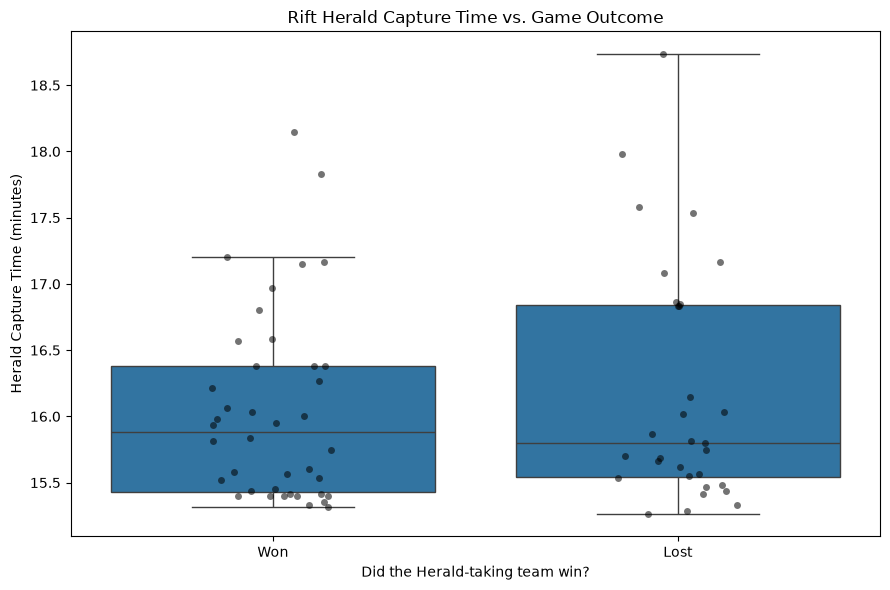

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# Determine whether the Herald-taking team won
herald_df["outcome"] = herald_df["herald_team_won"].map({
    True: "Won",
    False: "Lost"
})

# Set figure size
plt.figure(figsize=(9, 6))

# Boxplot
sns.boxplot(
    data=herald_df,
    x="outcome",
    y="herald_time_minutes",
    order=["Won", "Lost"],
    showfliers=False
)

# Overlay individual observations
sns.stripplot(
    data=herald_df,
    x="outcome",
    y="herald_time_minutes",
    order=["Won", "Lost"],
    color="black",
    alpha=0.55,
    jitter=0.15
)

plt.title("Rift Herald Capture Time vs. Game Outcome")
plt.xlabel("Did the Herald-taking team win?")
plt.ylabel("Herald Capture Time (minutes)")
plt.tight_layout()
plt.show()

In [53]:
from scipy.stats import mannwhitneyu

# Separate capture times by outcome
won_times = herald_df.loc[
    herald_df["outcome"] == "Won",
    "herald_time_minutes"
]

lost_times = herald_df.loc[
    herald_df["outcome"] == "Lost",
    "herald_time_minutes"
]

# Perform statistical test
statistic, p_value = mannwhitneyu(
    won_times,
    lost_times,
    alternative="two-sided"
)

print("Median Herald time when taker won:",
      round(won_times.median(), 2), "minutes")

print("Median Herald time when taker lost:",
      round(lost_times.median(), 2), "minutes")

print("Mann-Whitney U statistic:", statistic)
print("P-value:", round(p_value, 4))

Median Herald time when taker won: 15.88 minutes
Median Herald time when taker lost: 15.8 minutes
Mann-Whitney U statistic: 574.0
P-value: 0.5977


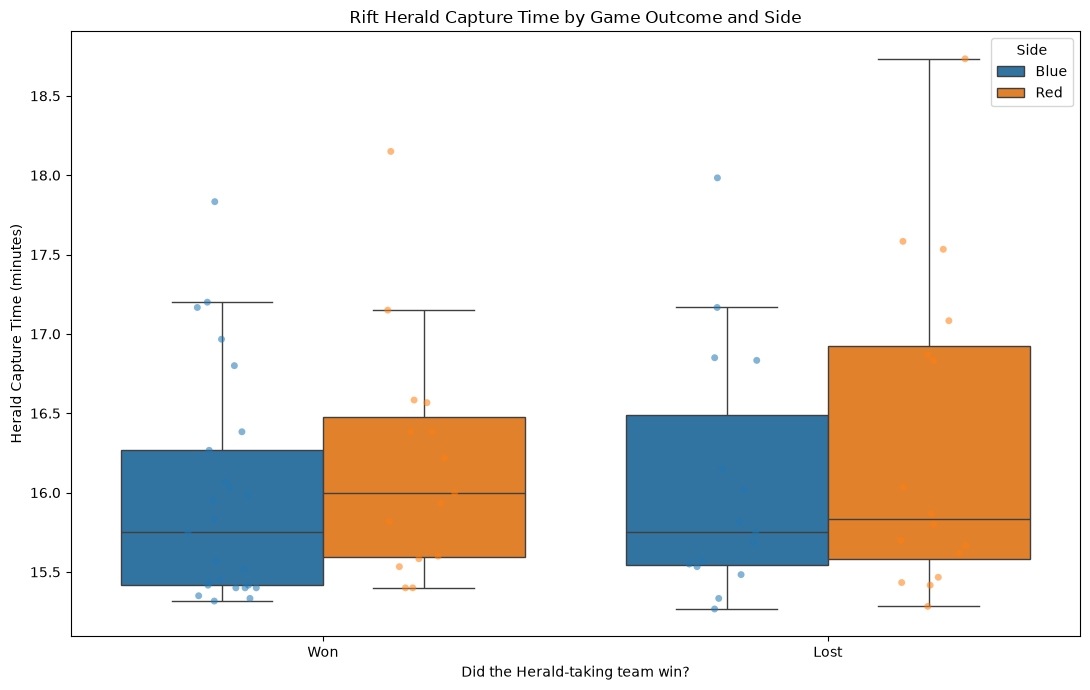

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

# Grouped boxplots
sns.boxplot(
    data=herald_df,
    x="outcome",
    y="herald_time_minutes",
    hue="side",
    order=["Won", "Lost"],
    hue_order=["Blue", "Red"],
    showfliers=False
)

# Overlay individual game observations
sns.stripplot(
    data=herald_df,
    x="outcome",
    y="herald_time_minutes",
    hue="side",
    order=["Won", "Lost"],
    hue_order=["Blue", "Red"],
    dodge=True,
    alpha=0.55,
    jitter=0.15,
    legend=False
)

plt.title("Rift Herald Capture Time by Game Outcome and Side")
plt.xlabel("Did the Herald-taking team win?")
plt.ylabel("Herald Capture Time (minutes)")
plt.legend(title="Side")
plt.tight_layout()
plt.show()

In [55]:
# Create a combined group variable
herald_df["side_outcome"] = (
    herald_df["side"] + " - " + herald_df["outcome"]
)

# Inspect group sizes and median capture times
group_summary = herald_df.groupby("side_outcome")[
    "herald_time_minutes"
].agg(["count", "median", "mean", "std"])

display(group_summary.round(2))

,count,median,mean,std
side_outcome,,,,
Blue - Lost,15,15.75,16.07,0.79
Blue - Won,25,15.75,15.97,0.71
Red - Lost,16,15.83,16.31,1.01
Red - Won,15,16.00,16.18,0.75


In [56]:
# kruskal-wallis test

from scipy.stats import kruskal

# Extract capture times for each group
blue_won = herald_df.loc[
    herald_df["side_outcome"] == "Blue - Won",
    "herald_time_minutes"
]

blue_lost = herald_df.loc[
    herald_df["side_outcome"] == "Blue - Lost",
    "herald_time_minutes"
]

red_won = herald_df.loc[
    herald_df["side_outcome"] == "Red - Won",
    "herald_time_minutes"
]

red_lost = herald_df.loc[
    herald_df["side_outcome"] == "Red - Lost",
    "herald_time_minutes"
]

# Run Kruskal-Wallis test
statistic, p_value = kruskal(
    blue_won,
    blue_lost,
    red_won,
    red_lost
)

print("Kruskal-Wallis statistic:", round(statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference between at least two groups.")
else:
    print("No statistically significant difference detected between the groups.")

Kruskal-Wallis statistic: 2.0491
P-value: 0.5623
No statistically significant difference detected between the groups.


In [58]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----------------------------------- ---- 10.0/11.3 MB 65.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 62.0 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ----


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
#pairwise comparisons

from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Store the four groups
groups = {
    "Blue - Won": blue_won,
    "Blue - Lost": blue_lost,
    "Red - Won": red_won,
    "Red - Lost": red_lost
}

# Compare every possible pair
results = []

for (name1, data1), (name2, data2) in combinations(groups.items(), 2):

    statistic, p_value = mannwhitneyu(
        data1,
        data2,
        alternative="two-sided"
    )

    results.append({
        "Group 1": name1,
        "Group 2": name2,
        "Median 1": data1.median(),
        "Median 2": data2.median(),
        "U statistic": statistic,
        "Raw p-value": p_value
    })

# Convert results into a DataFrame
pairwise_results = pd.DataFrame(results)

# Apply Bonferroni correction
pairwise_results["Adjusted p-value"] = multipletests(
    pairwise_results["Raw p-value"],
    method="bonferroni"
)[1]

pairwise_results["Significant"] = (
    pairwise_results["Adjusted p-value"] < 0.05
)

display(pairwise_results.round(4))

,Group 1,Group 2,Median 1,Median 2,U statistic,Raw p-value,Adjusted p-value,Significant
0,Blue - Won,Blue - Lost,15.75,15.7500,169.0,0.6149,1.0,False
1,Blue - Won,Red - Won,15.75,16.0000,144.0,0.2291,1.0,False
2,Blue - Won,Red - Lost,15.75,15.8333,158.0,0.2672,1.0,False
3,Blue - Lost,Red - Won,15.75,16.0000,96.0,0.5067,1.0,False
4,Blue - Lost,Red - Lost,15.75,15.8333,106.5,0.6073,1.0,False
5,Red - Won,Red - Lost,16.00,15.8333,118.0,0.9527,1.0,False


In [ ]:
# Calculate wins and total games for each side
blue_wins = elixir_game_table["blue_result"].sum()
red_wins = elixir_game_table["red_result"].sum()

total_games = len(elixir_game_table)

# Calculate win rates
blue_win_rate = blue_wins / total_games * 100
red_win_rate = red_wins / total_games * 100

# Display results
print(f"Total games: {total_games}")

print(f"Blue side wins: {blue_wins}")
print(f"Blue side win rate: {blue_win_rate:.2f}%")

print(f"\nRed side wins: {red_wins}")
print(f"Red side win rate: {red_win_rate:.2f}%")

#currently matches with online source which is good

Total games: 72
Blue side wins: 41
Blue side win rate: 56.94%

Red side wins: 31
Red side win rate: 43.06%


In [61]:
# Load the processed Worlds dataset
elixir_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "worlds_swiss_onward.csv"
)

# Keep only team-level rows
team_gold = elixir_df[
    elixir_df["position"] == "team"
].copy()

# Inspect the relevant columns
display(
    team_gold[
        ["gameid", "teamname", "side", "goldat15", "result"]
    ].head(10)
)

,gameid,teamname,side,goldat15,result
10,LOLTMNT02_482269,Invictus Gaming,Blue,28541.0,0
11,LOLTMNT02_482269,Gen.G,Red,26649.0,1
22,LOLTMNT02_483314,Top Esports,Blue,25843.0,0
23,LOLTMNT02_483314,Hanwha Life Esports,Red,26786.0,1
34,LOLTMNT02_483342,Movistar KOI,Blue,26376.0,1
35,LOLTMNT02_483342,Bilibili Gaming,Red,25288.0,0
46,LOLTMNT02_482292,Karmine Corp,Blue,25024.0,1
47,LOLTMNT02_482292,Anyone's Legend,Red,25485.0,0
58,LOLTMNT02_482304,Dplus Kia,Blue,24682.0,1
59,LOLTMNT02_482304,G2 Esports,Red,26867.0,0


In [62]:
# Keep the relevant gold and team information
gold_analysis = team_gold[
    ["gameid", "teamname", "side", "goldat15", "result"]
].copy()

# Get the team that secured Herald in each game
herald_lookup = herald_df[
    ["gameid", "team"]
].rename(columns={
    "team": "herald_team"
})

# Attach Herald information to the gold dataset
gold_analysis = gold_analysis.merge(
    herald_lookup,
    on="gameid",
    how="left"
)

# Identify whether each team secured Herald
gold_analysis["took_herald"] = (
    gold_analysis["teamname"] == gold_analysis["herald_team"]
)

# Rename result for clarity
gold_analysis = gold_analysis.rename(
    columns={
        "teamname": "team",
        "result": "game_result"
    }
)

# Check the resulting dataset
display(gold_analysis.head(15))

print("Total team observations:", len(gold_analysis))
print("Teams with Herald:", gold_analysis["took_herald"].sum())
print("Teams without Herald:", (~gold_analysis["took_herald"]).sum())
print("Missing goldat15:", gold_analysis["goldat15"].isna().sum())

,gameid,team,side,goldat15,game_result,herald_team,took_herald
0,LOLTMNT02_482269,Invictus Gaming,Blue,28541.0,0,Invictus Gaming,True
1,LOLTMNT02_482269,Gen.G,Red,26649.0,1,Invictus Gaming,False
2,LOLTMNT02_483314,Top Esports,Blue,25843.0,0,Hanwha Life Esports,False
3,LOLTMNT02_483314,Hanwha Life Esports,Red,26786.0,1,Hanwha Life Esports,True
4,LOLTMNT02_483342,Movistar KOI,Blue,26376.0,1,Bilibili Gaming,False
5,LOLTMNT02_483342,Bilibili Gaming,Red,25288.0,0,Bilibili Gaming,True
6,LOLTMNT02_482292,Karmine Corp,Blue,25024.0,1,Anyone s Legend,False
7,LOLTMNT02_482292,Anyone's Legend,Red,25485.0,0,Anyone s Legend,False
8,LOLTMNT02_482304,Dplus Kia,Blue,24682.0,1,G2 Esports,False
9,LOLTMNT02_482304,G2 Esports,Red,26867.0,0,G2 Esports,True


Total team observations: 144
Teams with Herald: 63
Teams without Herald: 81
Missing goldat15: 0


In [63]:
# Compare goldat15 between teams that did and did not take Herald
gold_comparison = gold_analysis.groupby("took_herald")["goldat15"].agg(
    ["count", "mean", "median", "std"]
)

gold_comparison.index = [
    "Did not take Herald",
    "Took Herald"
]

display(gold_comparison.round(2))

,count,mean,median,std
Did not take Herald,81,25973.53,26014.0,1265.32
Took Herald,63,26551.84,26543.0,1057.36


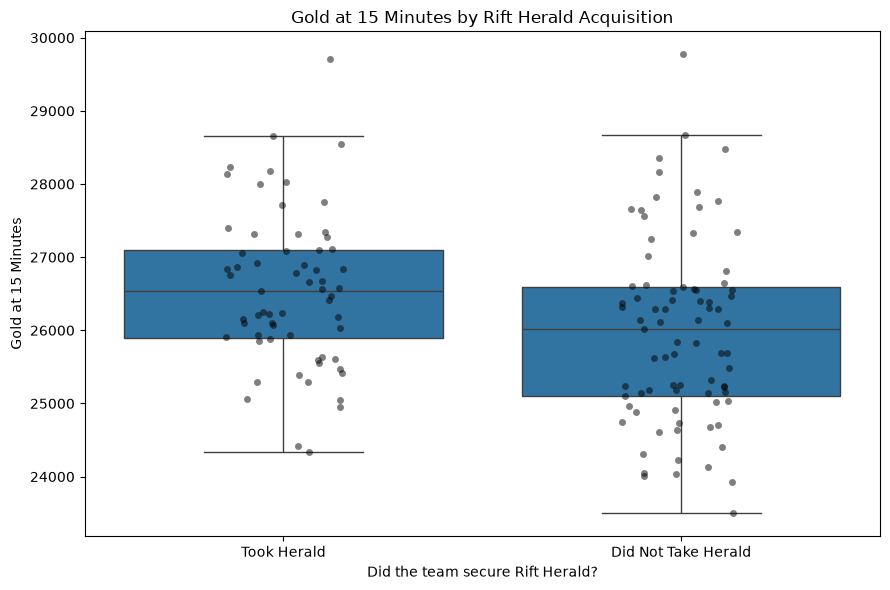

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Boxplot
sns.boxplot(
    data=gold_analysis,
    x="took_herald",
    y="goldat15",
    order=[True, False],
    showfliers=False
)

# Overlay individual observations
sns.stripplot(
    data=gold_analysis,
    x="took_herald",
    y="goldat15",
    order=[True, False],
    color="black",
    alpha=0.5,
    jitter=0.15
)

plt.title("Gold at 15 Minutes by Rift Herald Acquisition")
plt.xlabel("Did the team secure Rift Herald?")
plt.ylabel("Gold at 15 Minutes")
plt.xticks([0, 1], ["Took Herald", "Did Not Take Herald"])

plt.tight_layout()
plt.show()

In [65]:
from scipy.stats import mannwhitneyu

# Separate gold values into the two groups
herald_gold = gold_analysis.loc[
    gold_analysis["took_herald"] == True,
    "goldat15"
].dropna()

no_herald_gold = gold_analysis.loc[
    gold_analysis["took_herald"] == False,
    "goldat15"
].dropna()

# Perform the statistical test
statistic, p_value = mannwhitneyu(
    herald_gold,
    no_herald_gold,
    alternative="two-sided"
)

# Calculate median and mean differences
median_difference = herald_gold.median() - no_herald_gold.median()
mean_difference = herald_gold.mean() - no_herald_gold.mean()

print("Teams that took Herald:")
print("Mean gold at 15:", round(herald_gold.mean(), 2))
print("Median gold at 15:", round(herald_gold.median(), 2))

print("\nTeams that did not take Herald:")
print("Mean gold at 15:", round(no_herald_gold.mean(), 2))
print("Median gold at 15:", round(no_herald_gold.median(), 2))

print("\nDifference (Herald - No Herald):")
print("Mean difference:", round(mean_difference, 2))
print("Median difference:", round(median_difference, 2))

print("\nMann-Whitney U statistic:", round(statistic, 2))
print("P-value:", round(p_value, 5))

if p_value < 0.05:
    print("Statistically significant difference (p < 0.05).")
else:
    print("No statistically significant difference detected (p >= 0.05).")

Teams that took Herald:
Mean gold at 15: 26551.84
Median gold at 15: 26543.0

Teams that did not take Herald:
Mean gold at 15: 25973.53
Median gold at 15: 26014.0

Difference (Herald - No Herald):
Mean difference: 578.31
Median difference: 529.0

Mann-Whitney U statistic: 3299.0
P-value: 0.00263
Statistically significant difference (p < 0.05).


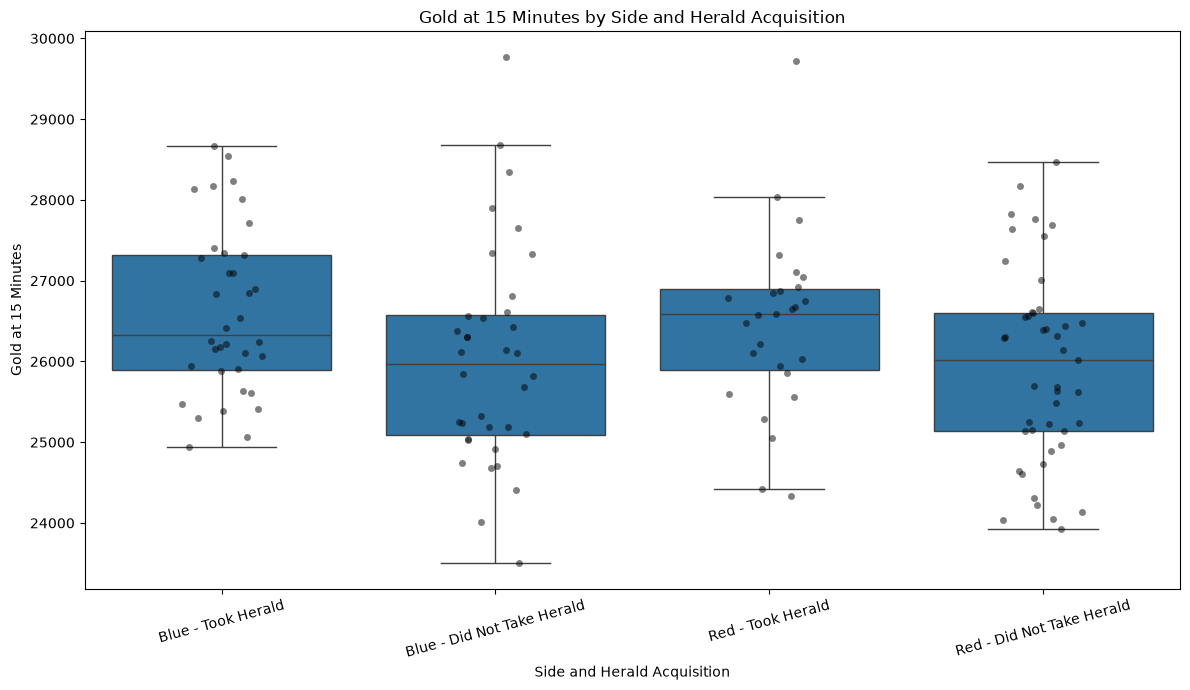

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a combined category for side and Herald acquisition
gold_analysis["side_herald"] = (
    gold_analysis["side"].str.title()
    + " - "
    + gold_analysis["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

# Set group order
group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

# Create figure
plt.figure(figsize=(12, 7))

# Boxplot
sns.boxplot(
    data=gold_analysis,
    x="side_herald",
    y="goldat15",
    order=group_order,
    showfliers=False
)

# Overlay individual observations
sns.stripplot(
    data=gold_analysis,
    x="side_herald",
    y="goldat15",
    order=group_order,
    color="black",
    alpha=0.5,
    jitter=0.15
)

plt.title("Gold at 15 Minutes by Side and Herald Acquisition")
plt.xlabel("Side and Herald Acquisition")
plt.ylabel("Gold at 15 Minutes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [67]:
gold_side_summary = gold_analysis.groupby(
    "side_herald"
)["goldat15"].agg(
    ["count", "mean", "median", "std"]
)

display(gold_side_summary.reindex(group_order).round(2))

,count,mean,median,std
side_herald,,,,
Blue - Took Herald,36,26618.42,26333.0,1031.81
Blue - Did Not Take Herald,36,26026.83,25974.5,1348.45
Red - Took Herald,27,26463.07,26583.0,1103.88
Red - Did Not Take Herald,45,25930.89,26014.0,1208.48


In [68]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Separate Blue side observations
blue_took = gold_analysis.loc[
    (gold_analysis["side"] == "Blue") &
    (gold_analysis["took_herald"] == True),
    "goldat15"
].dropna()

blue_did_not = gold_analysis.loc[
    (gold_analysis["side"] == "Blue") &
    (gold_analysis["took_herald"] == False),
    "goldat15"
].dropna()

# Separate Red side observations
red_took = gold_analysis.loc[
    (gold_analysis["side"] == "Red") &
    (gold_analysis["took_herald"] == True),
    "goldat15"
].dropna()

red_did_not = gold_analysis.loc[
    (gold_analysis["side"] == "Red") &
    (gold_analysis["took_herald"] == False),
    "goldat15"
].dropna()

# Run Mann-Whitney U tests
blue_stat, blue_p = mannwhitneyu(
    blue_took,
    blue_did_not,
    alternative="two-sided"
)

red_stat, red_p = mannwhitneyu(
    red_took,
    red_did_not,
    alternative="two-sided"
)

# Apply Bonferroni correction
adjusted_p = multipletests(
    [blue_p, red_p],
    method="bonferroni"
)[1]

# Create results table
results = pd.DataFrame({
    "Side": ["Blue", "Red"],
    "Took Herald Count": [len(blue_took), len(red_took)],
    "Did Not Take Count": [len(blue_did_not), len(red_did_not)],
    "Median Gold - Took": [
        blue_took.median(), red_took.median()
    ],
    "Median Gold - Did Not Take": [
        blue_did_not.median(), red_did_not.median()
    ],
    "Raw P-value": [blue_p, red_p],
    "Adjusted P-value": adjusted_p
})

results["Significant"] = results["Adjusted P-value"] < 0.05

display(results.round(4))

,Side,Took Herald Count,Did Not Take Count,Median Gold - Took,Median Gold - Did Not Take,Raw P-value,Adjusted P-value,Significant
0,Blue,36,36,26333.0,25974.5,0.0261,0.0523,False
1,Red,27,45,26583.0,26014.0,0.0467,0.0934,False


In [69]:
# Extract team-level XP at 15 minutes
xp_analysis = team_gold[
    ["gameid", "teamname", "side", "xpat15", "result"]
].copy()

# Attach Herald information
xp_analysis = xp_analysis.merge(
    herald_lookup,
    on="gameid",
    how="left"
)

# Identify whether each team secured Herald
xp_analysis["took_herald"] = (
    xp_analysis["teamname"] == xp_analysis["herald_team"]
)

# Create four comparison groups
xp_analysis["side_herald"] = (
    xp_analysis["side"].str.title()
    + " - "
    + xp_analysis["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

# Check the data
print("Total team observations:", len(xp_analysis))
print("Missing XP values:", xp_analysis["xpat15"].isna().sum())

display(xp_analysis.head(10))

Total team observations: 144
Missing XP values: 0


,gameid,teamname,side,xpat15,result,herald_team,took_herald,side_herald
0,LOLTMNT02_482269,Invictus Gaming,Blue,32478.0,0,Invictus Gaming,True,Blue - Took Herald
1,LOLTMNT02_482269,Gen.G,Red,32600.0,1,Invictus Gaming,False,Red - Did Not Take Herald
2,LOLTMNT02_483314,Top Esports,Blue,31711.0,0,Hanwha Life Esports,False,Blue - Did Not Take Herald
3,LOLTMNT02_483314,Hanwha Life Esports,Red,33236.0,1,Hanwha Life Esports,True,Red - Took Herald
4,LOLTMNT02_483342,Movistar KOI,Blue,32413.0,1,Bilibili Gaming,False,Blue - Did Not Take Herald
5,LOLTMNT02_483342,Bilibili Gaming,Red,33444.0,0,Bilibili Gaming,True,Red - Took Herald
6,LOLTMNT02_482292,Karmine Corp,Blue,31932.0,1,Anyone s Legend,False,Blue - Did Not Take Herald
7,LOLTMNT02_482292,Anyone's Legend,Red,31157.0,0,Anyone s Legend,False,Red - Did Not Take Herald
8,LOLTMNT02_482304,Dplus Kia,Blue,33324.0,1,G2 Esports,False,Blue - Did Not Take Herald
9,LOLTMNT02_482304,G2 Esports,Red,31857.0,0,G2 Esports,True,Red - Took Herald


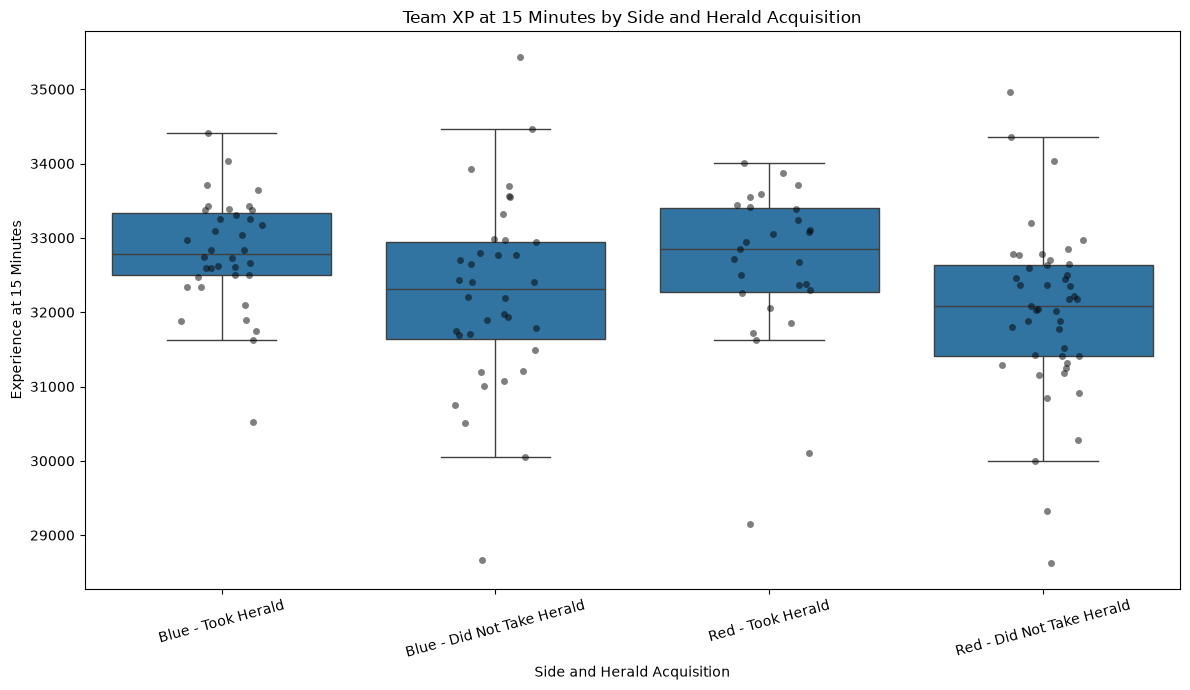

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat15",
    order=group_order,
    showfliers=False
)

sns.stripplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat15",
    order=group_order,
    color="black",
    alpha=0.5,
    jitter=0.15
)

plt.title("Team XP at 15 Minutes by Side and Herald Acquisition")
plt.xlabel("Side and Herald Acquisition")
plt.ylabel("Experience at 15 Minutes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [71]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Blue side
blue_took = xp_analysis.loc[
    (xp_analysis["side"] == "Blue") &
    (xp_analysis["took_herald"] == True),
    "xpat15"
].dropna()

blue_did_not = xp_analysis.loc[
    (xp_analysis["side"] == "Blue") &
    (xp_analysis["took_herald"] == False),
    "xpat15"
].dropna()

# Red side
red_took = xp_analysis.loc[
    (xp_analysis["side"] == "Red") &
    (xp_analysis["took_herald"] == True),
    "xpat15"
].dropna()

red_did_not = xp_analysis.loc[
    (xp_analysis["side"] == "Red") &
    (xp_analysis["took_herald"] == False),
    "xpat15"
].dropna()

# Run Mann-Whitney U tests
blue_stat, blue_p = mannwhitneyu(
    blue_took, blue_did_not,
    alternative="two-sided"
)

red_stat, red_p = mannwhitneyu(
    red_took, red_did_not,
    alternative="two-sided"
)

# Bonferroni correction
adjusted_p = multipletests(
    [blue_p, red_p],
    method="bonferroni"
)[1]

# Summarize results
xp_results = pd.DataFrame({
    "Side": ["Blue", "Red"],
    "Took Herald Count": [len(blue_took), len(red_took)],
    "Did Not Take Count": [len(blue_did_not), len(red_did_not)],
    "Median XP - Took": [
        blue_took.median(), red_took.median()
    ],
    "Median XP - Did Not Take": [
        blue_did_not.median(), red_did_not.median()
    ],
    "Raw P-value": [blue_p, red_p],
    "Adjusted P-value": adjusted_p
})

xp_results["Significant"] = (
    xp_results["Adjusted P-value"] < 0.05
)

display(xp_results.round(4))

,Side,Took Herald Count,Did Not Take Count,Median XP - Took,Median XP - Did Not Take,Raw P-value,Adjusted P-value,Significant
0,Blue,36,36,32786.5,32307.5,0.0219,0.0438,True
1,Red,27,45,32847.0,32079.0,0.0028,0.0056,True


In [72]:
# Extract team-level XP data
xp_analysis = elixir_df[
    elixir_df["position"] == "team"
][
    ["gameid", "teamname", "side", "xpat10", "xpat15"]
].copy()

# Attach Herald information
xp_analysis = xp_analysis.merge(
    herald_lookup,
    on="gameid",
    how="left"
)

# Identify whether each team secured Herald
xp_analysis["took_herald"] = (
    xp_analysis["teamname"] == xp_analysis["herald_team"]
)

# Create four comparison groups
xp_analysis["side_herald"] = (
    xp_analysis["side"].str.title()
    + " - "
    + xp_analysis["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

# Check the dataset
print("Total team observations:", len(xp_analysis))
print("Missing XP at 10:", xp_analysis["xpat10"].isna().sum())
print("Missing XP at 15:", xp_analysis["xpat15"].isna().sum())

display(xp_analysis.head(10))

Total team observations: 144
Missing XP at 10: 0
Missing XP at 15: 0


,gameid,teamname,side,xpat10,xpat15,herald_team,took_herald,side_herald
0,LOLTMNT02_482269,Invictus Gaming,Blue,20189.0,32478.0,Invictus Gaming,True,Blue - Took Herald
1,LOLTMNT02_482269,Gen.G,Red,19903.0,32600.0,Invictus Gaming,False,Red - Did Not Take Herald
2,LOLTMNT02_483314,Top Esports,Blue,20947.0,31711.0,Hanwha Life Esports,False,Blue - Did Not Take Herald
3,LOLTMNT02_483314,Hanwha Life Esports,Red,21182.0,33236.0,Hanwha Life Esports,True,Red - Took Herald
4,LOLTMNT02_483342,Movistar KOI,Blue,21072.0,32413.0,Bilibili Gaming,False,Blue - Did Not Take Herald
5,LOLTMNT02_483342,Bilibili Gaming,Red,20640.0,33444.0,Bilibili Gaming,True,Red - Took Herald
6,LOLTMNT02_482292,Karmine Corp,Blue,19662.0,31932.0,Anyone s Legend,False,Blue - Did Not Take Herald
7,LOLTMNT02_482292,Anyone's Legend,Red,20486.0,31157.0,Anyone s Legend,False,Red - Did Not Take Herald
8,LOLTMNT02_482304,Dplus Kia,Blue,20694.0,33324.0,G2 Esports,False,Blue - Did Not Take Herald
9,LOLTMNT02_482304,G2 Esports,Red,19235.0,31857.0,G2 Esports,True,Red - Took Herald


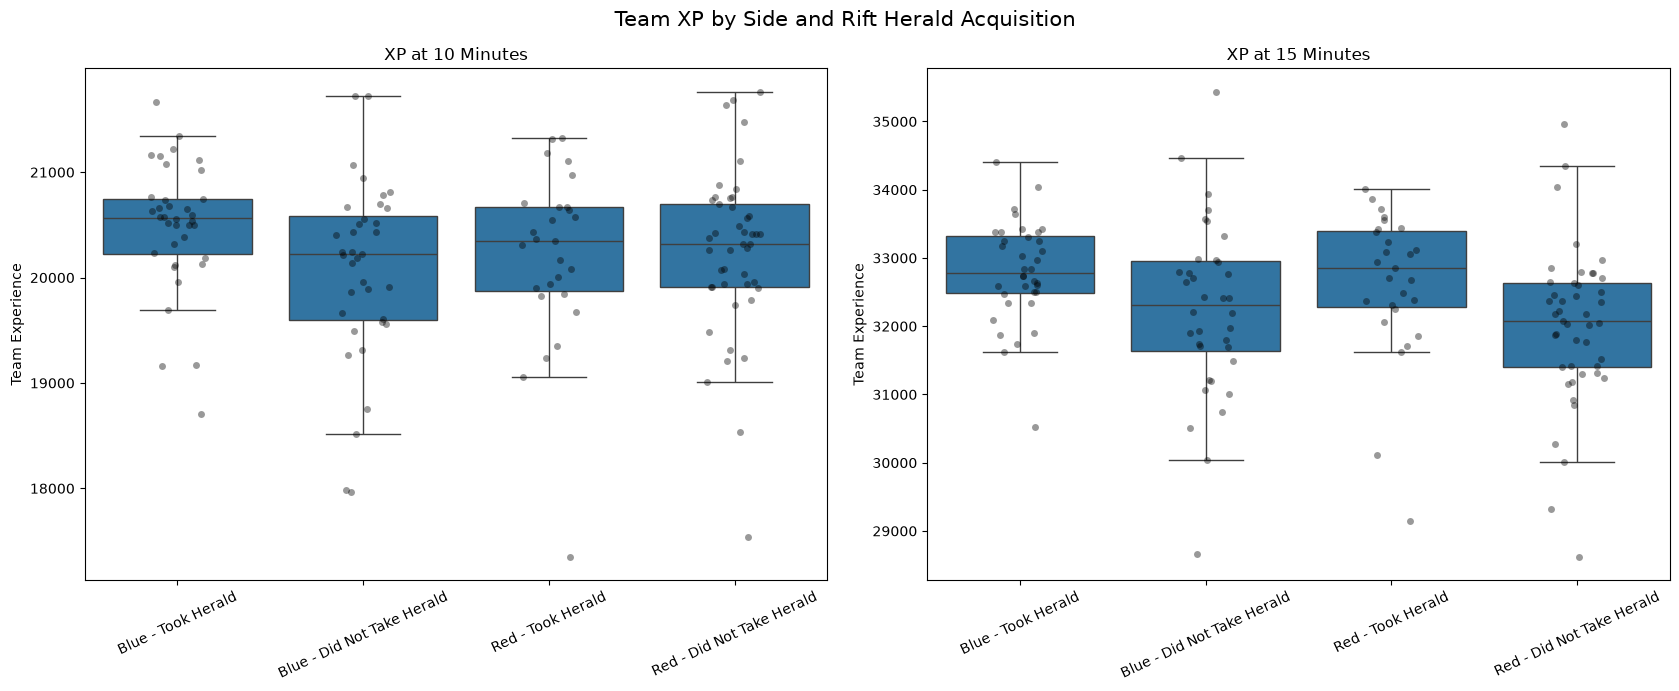

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# XP at 10 minutes
sns.boxplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat10",
    order=group_order,
    showfliers=False,
    ax=axes[0]
)

sns.stripplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat10",
    order=group_order,
    color="black",
    alpha=0.4,
    jitter=0.15,
    ax=axes[0]
)

axes[0].set_title("XP at 10 Minutes")
axes[0].set_xlabel("")
axes[0].set_ylabel("Team Experience")
axes[0].tick_params(axis="x", rotation=25)

# XP at 15 minutes
sns.boxplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat15",
    order=group_order,
    showfliers=False,
    ax=axes[1]
)

sns.stripplot(
    data=xp_analysis,
    x="side_herald",
    y="xpat15",
    order=group_order,
    color="black",
    alpha=0.4,
    jitter=0.15,
    ax=axes[1]
)

axes[1].set_title("XP at 15 Minutes")
axes[1].set_xlabel("")
axes[1].set_ylabel("Team Experience")
axes[1].tick_params(axis="x", rotation=25)

fig.suptitle(
    "Team XP by Side and Rift Herald Acquisition",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [74]:
from scipy.stats import mannwhitneyu
import pandas as pd

# Define the four comparisons
comparisons = [
    ("Blue", "xpat10"),
    ("Red", "xpat10"),
    ("Blue", "xpat15"),
    ("Red", "xpat15")
]

results = []

for side, metric in comparisons:

    took = xp_analysis.loc[
        (xp_analysis["side"] == side) &
        (xp_analysis["took_herald"] == True),
        metric
    ].dropna()

    did_not = xp_analysis.loc[
        (xp_analysis["side"] == side) &
        (xp_analysis["took_herald"] == False),
        metric
    ].dropna()

    statistic, p_value = mannwhitneyu(
        took,
        did_not,
        alternative="two-sided"
    )

    results.append({
        "Side": side,
        "Time": metric,
        "Took Herald Count": len(took),
        "No Herald Count": len(did_not),
        "Median XP - Took": took.median(),
        "Median XP - No Herald": did_not.median(),
        "Median Difference": took.median() - did_not.median(),
        "Raw P-value": p_value
    })

xp_test_results = pd.DataFrame(results)

# Bonferroni correction for all four tests
xp_test_results["Adjusted P-value"] = (
    xp_test_results["Raw P-value"] * 4
).clip(upper=1)

xp_test_results["Significant"] = (
    xp_test_results["Adjusted P-value"] < 0.05
)

display(xp_test_results.round(4))

,Side,Time,Took Herald Count,No Herald Count,Median XP - Took,Median XP - No Herald,Median Difference,Raw P-value,Adjusted P-value,Significant
0,Blue,xpat10,36,36,20565.5,20220.5,345.0,0.0159,0.0638,False
1,Red,xpat10,27,45,20349.0,20318.0,31.0,0.9722,1.0000,False
2,Blue,xpat15,36,36,32786.5,32307.5,479.0,0.0219,0.0876,False
3,Red,xpat15,27,45,32847.0,32079.0,768.0,0.0028,0.0112,True


In [75]:
# Select the team-level rows and XP columns
xp_progression = elixir_df[
    elixir_df["position"] == "team"
][
    ["gameid", "teamname", "side", "xpat10", "xpat15", "xpat20", "xpat25"]
].copy()

# Attach the team that took Herald in each game
xp_progression = xp_progression.merge(
    herald_lookup,
    on="gameid",
    how="left"
)

# Identify whether each team took Herald
xp_progression["took_herald"] = (
    xp_progression["teamname"] == xp_progression["herald_team"]
)

# Create a label identifying both side and Herald status
xp_progression["side_herald"] = (
    xp_progression["side"].str.title()
    + " - "
    + xp_progression["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

display(xp_progression.head())

,gameid,teamname,side,xpat10,xpat15,xpat20,xpat25,herald_team,took_herald,side_herald
0,LOLTMNT02_482269,Invictus Gaming,Blue,20189.0,32478.0,42584.0,51253.0,Invictus Gaming,True,Blue - Took Herald
1,LOLTMNT02_482269,Gen.G,Red,19903.0,32600.0,48067.0,67256.0,Invictus Gaming,False,Red - Did Not Take Herald
2,LOLTMNT02_483314,Top Esports,Blue,20947.0,31711.0,39571.0,NaN,Hanwha Life Esports,False,Blue - Did Not Take Herald
3,LOLTMNT02_483314,Hanwha Life Esports,Red,21182.0,33236.0,48510.0,NaN,Hanwha Life Esports,True,Red - Took Herald
4,LOLTMNT02_483342,Movistar KOI,Blue,21072.0,32413.0,44419.0,54699.0,Bilibili Gaming,False,Blue - Did Not Take Herald


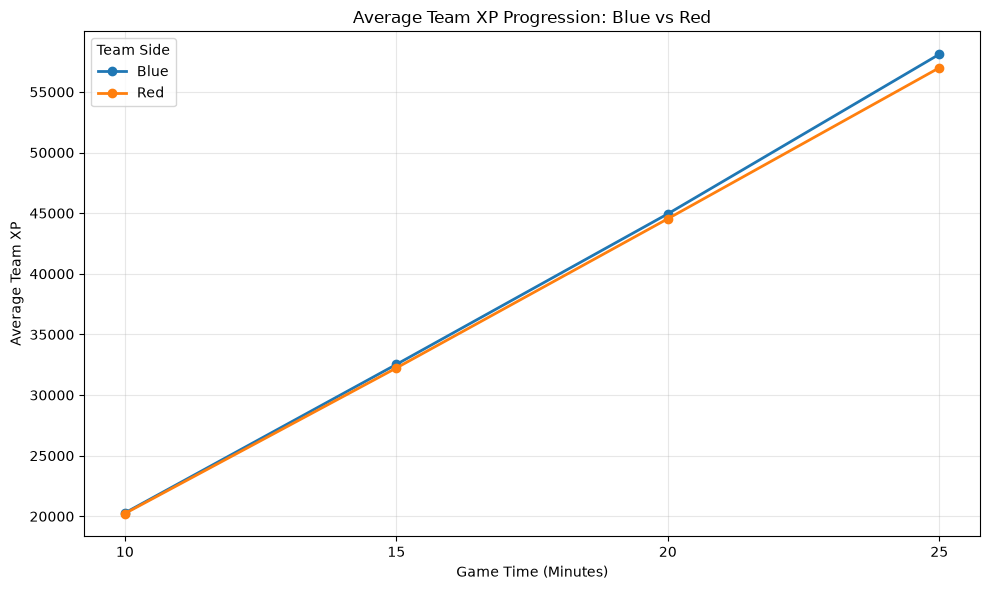

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

xp_columns = ["xpat10", "xpat15", "xpat20", "xpat25"]

# Calculate average XP for each side
overall_xp = xp_progression.groupby("side")[xp_columns].mean()

# Rename columns for cleaner graph labels
overall_xp.columns = [10, 15, 20, 25]

# Plot
plt.figure(figsize=(10, 6))

for side in ["Blue", "Red"]:
    plt.plot(
        overall_xp.columns,
        overall_xp.loc[side],
        marker="o",
        linewidth=2,
        label=side
    )

plt.title("Average Team XP Progression: Blue vs Red")
plt.xlabel("Game Time (Minutes)")
plt.ylabel("Average Team XP")
plt.xticks([10, 15, 20, 25])
plt.legend(title="Team Side")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

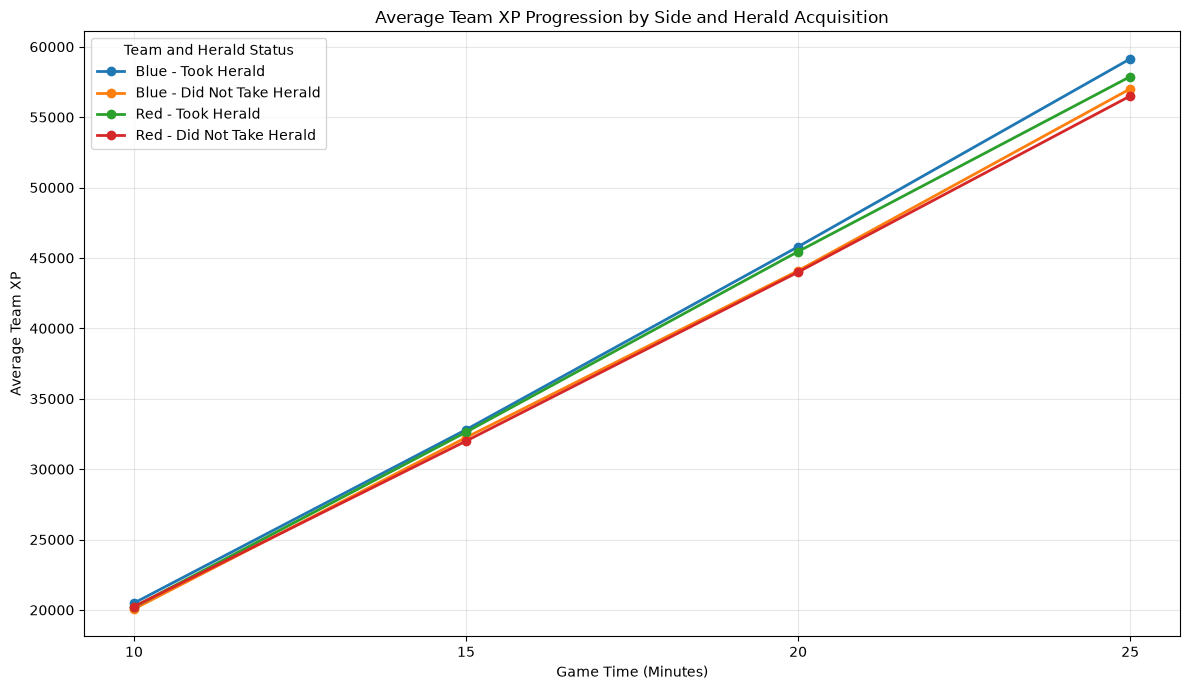

In [77]:
# Calculate average XP for each side and Herald group
herald_xp = xp_progression.groupby("side_herald")[xp_columns].mean()

# Rename columns for graph labels
herald_xp.columns = [10, 15, 20, 25]

group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

# Plot
plt.figure(figsize=(12, 7))

for group in group_order:
    plt.plot(
        herald_xp.columns,
        herald_xp.loc[group],
        marker="o",
        linewidth=2,
        label=group
    )

plt.title("Average Team XP Progression by Side and Herald Acquisition")
plt.xlabel("Game Time (Minutes)")
plt.ylabel("Average Team XP")
plt.xticks([10, 15, 20, 25])
plt.legend(title="Team and Herald Status")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [78]:
# Get the team that secured Herald in each game
herald_teams = herald_df[
    ["gameid", "team", "side", "herald_time_minutes"]
].copy()

herald_teams = herald_teams.rename(
    columns={"team": "herald_team"}
)

# Get individual players and their champions
player_champions = elixir_df[
    elixir_df["position"] != "team"
][
    ["gameid", "teamname", "position", "champion"]
].copy()

# Match each Herald-taking team to its five players
herald_champions = player_champions.merge(
    herald_teams,
    on="gameid",
    how="inner"
)

# Keep only players on the team that secured Herald
herald_champions = herald_champions[
    herald_champions["teamname"] == herald_champions["herald_team"]
].copy()

# Display the champion composition for each game
herald_champions = herald_champions.sort_values(
    ["gameid", "position"]
)

display(
    herald_champions[
        ["gameid", "herald_team", "side", "herald_time_minutes",
         "position", "champion"]
    ].head(25)
)

,gameid,herald_team,side,herald_time_minutes,position,champion
3,LOLTMNT02_482269,Invictus Gaming,Blue,15.333333,bot,Jhin
1,LOLTMNT02_482269,Invictus Gaming,Blue,15.333333,jng,Jarvan IV
2,LOLTMNT02_482269,Invictus Gaming,Blue,15.333333,mid,Aurora
4,LOLTMNT02_482269,Invictus Gaming,Blue,15.333333,sup,Alistar
0,LOLTMNT02_482269,Invictus Gaming,Blue,15.333333,top,Rumble
48,LOLTMNT02_482304,G2 Esports,Red,16.866667,bot,Kalista
46,LOLTMNT02_482304,G2 Esports,Red,16.866667,jng,Jarvan IV
47,LOLTMNT02_482304,G2 Esports,Red,16.866667,mid,Viktor
49,LOLTMNT02_482304,G2 Esports,Red,16.866667,sup,Renata Glasc
45,LOLTMNT02_482304,G2 Esports,Red,16.866667,top,K'Sante


In [79]:
champion_counts = (
    herald_champions["champion"]
    .value_counts()
    .reset_index()
)

champion_counts.columns = ["Champion", "Herald Games"]

display(champion_counts.head(20))

,Champion,Herald Games
0,Lee Sin,13
1,Ezreal,12
2,Jhin,11
3,Nautilus,11
4,Alistar,10
5,Ambessa,10
6,Rumble,8
7,K'Sante,8
8,Olaf,8
9,Orianna,8


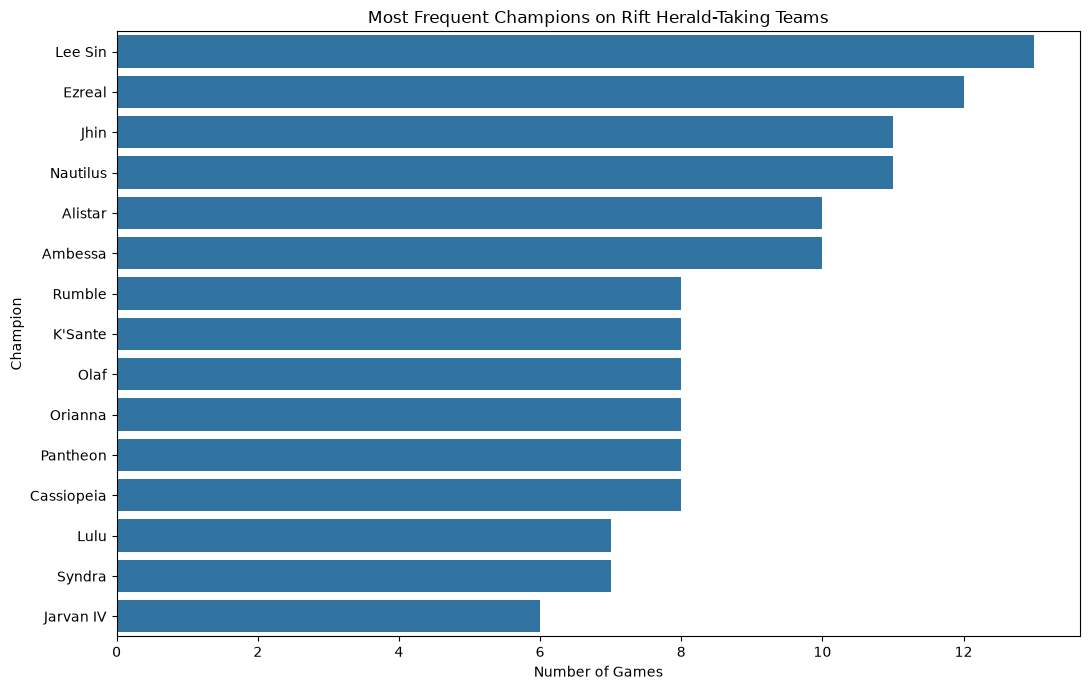

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

top_champions = champion_counts.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_champions,
    x="Herald Games",
    y="Champion"
)

plt.title("Most Frequent Champions on Rift Herald-Taking Teams")
plt.xlabel("Number of Games")
plt.ylabel("Champion")
plt.tight_layout()
plt.show()

In [81]:
# Get individual players and their champions
player_champions = elixir_df[
    elixir_df["position"] != "team"
][
    ["gameid", "teamname", "position", "champion"]
].copy()

# Attach the team that secured Herald in each game
non_herald_champions = player_champions.merge(
    herald_teams,
    on="gameid",
    how="inner"
)

# Keep only players NOT on the Herald-taking team
non_herald_champions = non_herald_champions[
    non_herald_champions["teamname"] != non_herald_champions["herald_team"]
].copy()

# Sort and display
non_herald_champions = non_herald_champions.sort_values(
    ["gameid", "position"]
)

display(
    non_herald_champions[
        ["gameid", "teamname", "side", "herald_team",
         "herald_time_minutes", "position", "champion"]
    ].head(25)
)

,gameid,teamname,side,herald_team,herald_time_minutes,position,champion
8,LOLTMNT02_482269,Gen.G,Blue,Invictus Gaming,15.333333,bot,Corki
6,LOLTMNT02_482269,Gen.G,Blue,Invictus Gaming,15.333333,jng,Qiyana
7,LOLTMNT02_482269,Gen.G,Blue,Invictus Gaming,15.333333,mid,Akali
9,LOLTMNT02_482269,Gen.G,Blue,Invictus Gaming,15.333333,sup,Nautilus
5,LOLTMNT02_482269,Gen.G,Blue,Invictus Gaming,15.333333,top,Ornn
33,LOLTMNT02_482292,Karmine Corp,Red,Anyone s Legend,15.433333,bot,Kalista
38,LOLTMNT02_482292,Anyone's Legend,Red,Anyone s Legend,15.433333,bot,Miss Fortune
31,LOLTMNT02_482292,Karmine Corp,Red,Anyone s Legend,15.433333,jng,Jarvan IV
36,LOLTMNT02_482292,Anyone's Legend,Red,Anyone s Legend,15.433333,jng,Nocturne
32,LOLTMNT02_482292,Karmine Corp,Red,Anyone s Legend,15.433333,mid,Orianna


In [82]:
non_herald_champion_counts = (
    non_herald_champions["champion"]
    .value_counts()
    .reset_index()
)

non_herald_champion_counts.columns = [
    "Champion",
    "Games Without Herald"
]

display(non_herald_champion_counts.head(20))

,Champion,Games Without Herald
0,Jarvan IV,13
1,Orianna,13
2,Qiyana,12
3,Nautilus,11
4,Syndra,11
5,Alistar,11
6,Rumble,11
7,Ezreal,11
8,Nocturne,10
9,Lee Sin,10


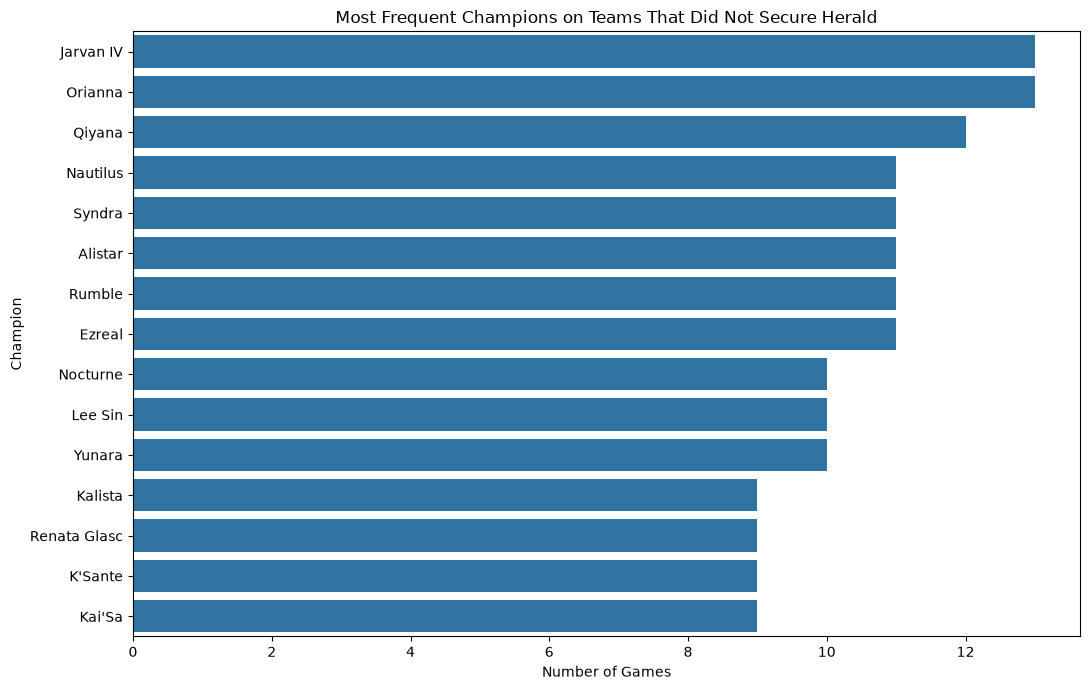

In [83]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=non_herald_champion_counts.head(15),
    x="Games Without Herald",
    y="Champion"
)

plt.title("Most Frequent Champions on Teams That Did Not Secure Herald")
plt.xlabel("Number of Games")
plt.ylabel("Champion")
plt.tight_layout()
plt.show()

In [84]:
# Get all team-level Herald information
game_teams = elixir_df[
    elixir_df["position"] == "team"
][
    ["gameid", "teamname", "side"]
].copy()

# Attach the Herald-taking team
game_teams = game_teams.merge(
    herald_teams[["gameid", "herald_team"]],
    on="gameid",
    how="left"
)

# Identify whether this team took Herald
game_teams["took_herald"] = (
    game_teams["teamname"] == game_teams["herald_team"]
)

# Get individual player champions
player_champions = elixir_df[
    elixir_df["position"] != "team"
][
    ["gameid", "teamname", "position", "champion"]
].copy()

# Attach each team's Herald outcome and side
champion_analysis = player_champions.merge(
    game_teams,
    on=["gameid", "teamname"],
    how="left",
    validate="many_to_one"
)

# Create four comparison groups
champion_analysis["side_herald"] = (
    champion_analysis["side"].str.title()
    + " - "
    + champion_analysis["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

display(champion_analysis.head(10))

,gameid,teamname,position,champion,side,herald_team,took_herald,side_herald
0,LOLTMNT02_482269,Invictus Gaming,top,Rumble,Blue,Invictus Gaming,True,Blue - Took Herald
1,LOLTMNT02_482269,Invictus Gaming,jng,Jarvan IV,Blue,Invictus Gaming,True,Blue - Took Herald
2,LOLTMNT02_482269,Invictus Gaming,mid,Aurora,Blue,Invictus Gaming,True,Blue - Took Herald
3,LOLTMNT02_482269,Invictus Gaming,bot,Jhin,Blue,Invictus Gaming,True,Blue - Took Herald
4,LOLTMNT02_482269,Invictus Gaming,sup,Alistar,Blue,Invictus Gaming,True,Blue - Took Herald
5,LOLTMNT02_482269,Gen.G,top,Ornn,Red,Invictus Gaming,False,Red - Did Not Take Herald
6,LOLTMNT02_482269,Gen.G,jng,Qiyana,Red,Invictus Gaming,False,Red - Did Not Take Herald
7,LOLTMNT02_482269,Gen.G,mid,Akali,Red,Invictus Gaming,False,Red - Did Not Take Herald
8,LOLTMNT02_482269,Gen.G,bot,Corki,Red,Invictus Gaming,False,Red - Did Not Take Herald
9,LOLTMNT02_482269,Gen.G,sup,Nautilus,Red,Invictus Gaming,False,Red - Did Not Take Herald


In [85]:
champion_group_counts = pd.crosstab(
    champion_analysis["champion"],
    champion_analysis["side_herald"]
)

# Ensure all four groups are displayed
group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

champion_group_counts = champion_group_counts.reindex(
    columns=group_order,
    fill_value=0
)

# Show champions with the most total appearances
champion_group_counts["Total"] = champion_group_counts.sum(axis=1)

champion_group_counts = champion_group_counts.sort_values(
    "Total",
    ascending=False
)

display(champion_group_counts.head(25))

side_herald,Blue - Took Herald,Blue - Did Not Take Herald,Red - Took Herald,Red - Did Not Take Herald,Total
champion,,,,,
Lee Sin,6,4,7,7,24
Ezreal,7,7,5,4,23
Nautilus,8,5,3,6,22
Alistar,6,2,4,9,21
Orianna,3,8,5,5,21
Rumble,4,3,4,9,20
Jarvan IV,4,9,2,4,19
Ambessa,6,7,4,2,19
Qiyana,3,3,3,9,18


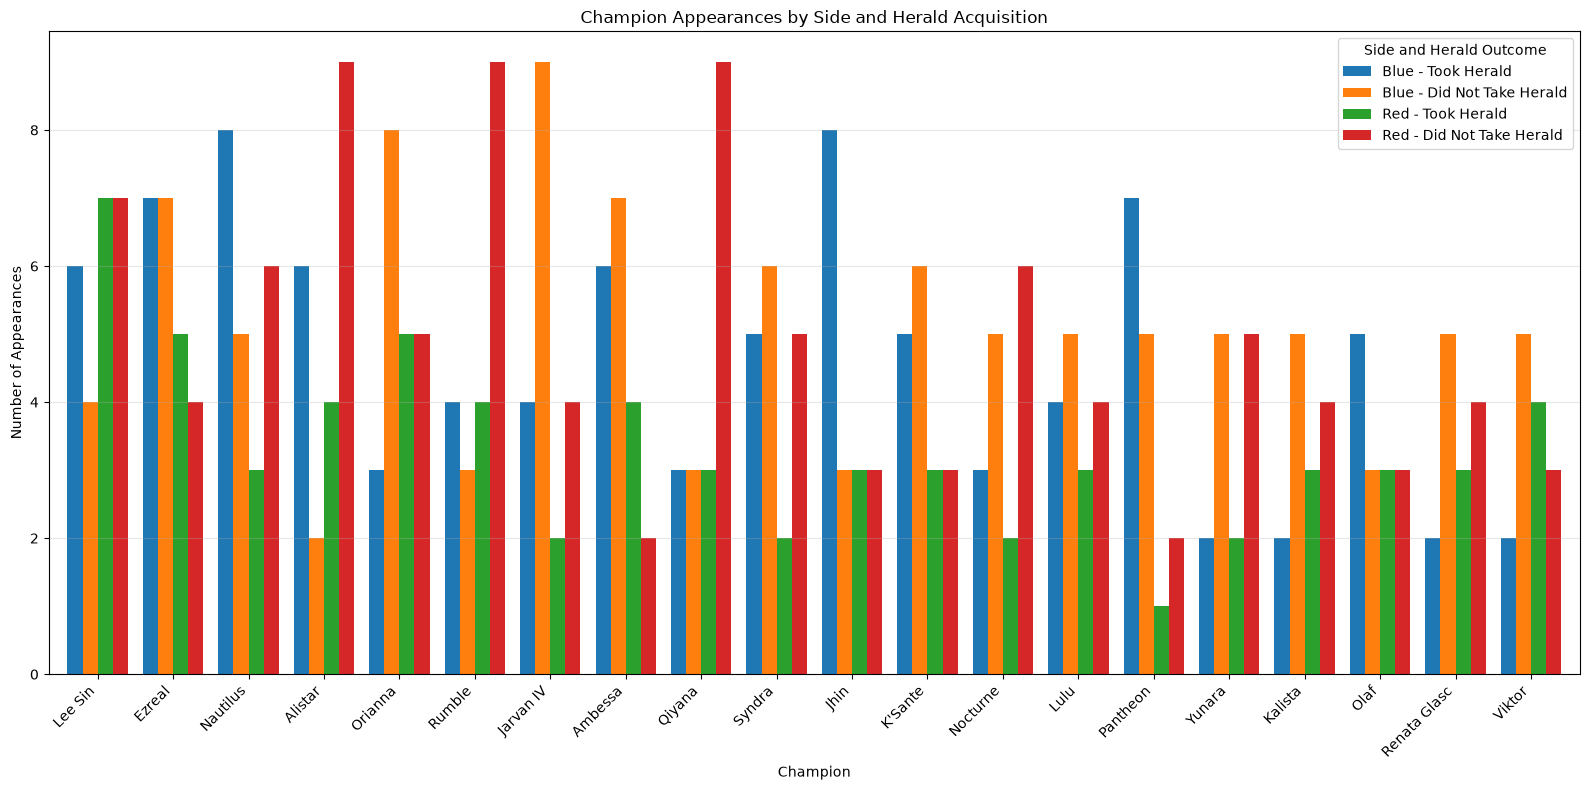

In [86]:
top_20 = champion_group_counts.head(20).drop(
    columns="Total"
)

top_20.plot(
    kind="bar",
    figsize=(16, 8),
    width=0.8
)

plt.title("Champion Appearances by Side and Herald Acquisition")
plt.xlabel("Champion")
plt.ylabel("Number of Appearances")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Side and Herald Outcome")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [89]:
# Get all team-level Herald information
game_teams = elixir_df[
    elixir_df["position"] == "team"
][
    ["gameid", "teamname", "side"]
].copy()

game_teams = game_teams.merge(
    herald_teams[["gameid", "herald_team"]],
    on="gameid",
    how="left"
)

game_teams["took_herald"] = (
    game_teams["teamname"] == game_teams["herald_team"]
)

# Get Qiyana player observations
qiyana_df = elixir_df[
    (elixir_df["position"] != "team") &
    (elixir_df["champion"].str.casefold() == "qiyana")
].copy()

# Remove side if it already exists, so the merge doesn't create side_x/side_y
if "side" in qiyana_df.columns:
    qiyana_df = qiyana_df.drop(columns=["side"])

# Attach team side and Herald outcome
qiyana_df = qiyana_df.merge(
    game_teams[
        ["gameid", "teamname", "side", "herald_team", "took_herald"]
    ],
    on=["gameid", "teamname"],
    how="left",
    validate="many_to_one"
)

# Create comparison groups
qiyana_df["side_herald"] = (
    qiyana_df["side"].str.title()
    + " - "
    + qiyana_df["took_herald"].map({
        True: "Took Herald",
        False: "Did Not Take Herald"
    })
)

print("Total Qiyana appearances:", len(qiyana_df))
print("\nAppearances by group:")
display(qiyana_df["side_herald"].value_counts())

display(qiyana_df.head())

Total Qiyana appearances: 18

Appearances by group:


side_herald
Red - Did Not Take Herald     9
Red - Took Herald             3
Blue - Did Not Take Herald    3
Blue - Took Herald            3
Name: count, dtype: int64

,gameid,datacompleteness,url,league,year,split,playoffs,date,game,patch,...,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25,side,herald_team,took_herald,side_herald
0,LOLTMNT02_482269,complete,NaN,WLDs,2026,NaN,0,2026-10-23 17:21:18,1,16.2,...,4.0,10.0,1.0,0.0,7.0,2.0,Red,Invictus Gaming,False,Red - Did Not Take Herald
1,LOLTMNT02_482313,complete,NaN,WLDs,2026,NaN,0,2026-10-23 22:17:20,1,16.2,...,3.0,1.0,1.0,3.0,4.0,1.0,Red,CTBC Flying Oyster,True,Red - Took Herald
2,LOLTMNT02_482559,complete,NaN,WLDs,2026,NaN,0,2026-10-24 18:08:21,1,16.2,...,2.0,3.0,2.0,0.0,5.0,1.0,Blue,CTBC Flying Oyster,False,Blue - Did Not Take Herald
3,LOLTMNT02_482587,complete,NaN,WLDs,2026,NaN,0,2026-10-24 21:18:13,1,16.2,...,2.0,4.0,2.0,3.0,9.0,2.0,Blue,Team Secret Whales,True,Blue - Took Herald
4,LOLTMNT02_482599,complete,NaN,WLDs,2026,NaN,0,2026-10-24 22:24:48,1,16.2,...,0.0,8.0,2.0,1.0,3.0,4.0,Red,Gen.G,True,Red - Took Herald


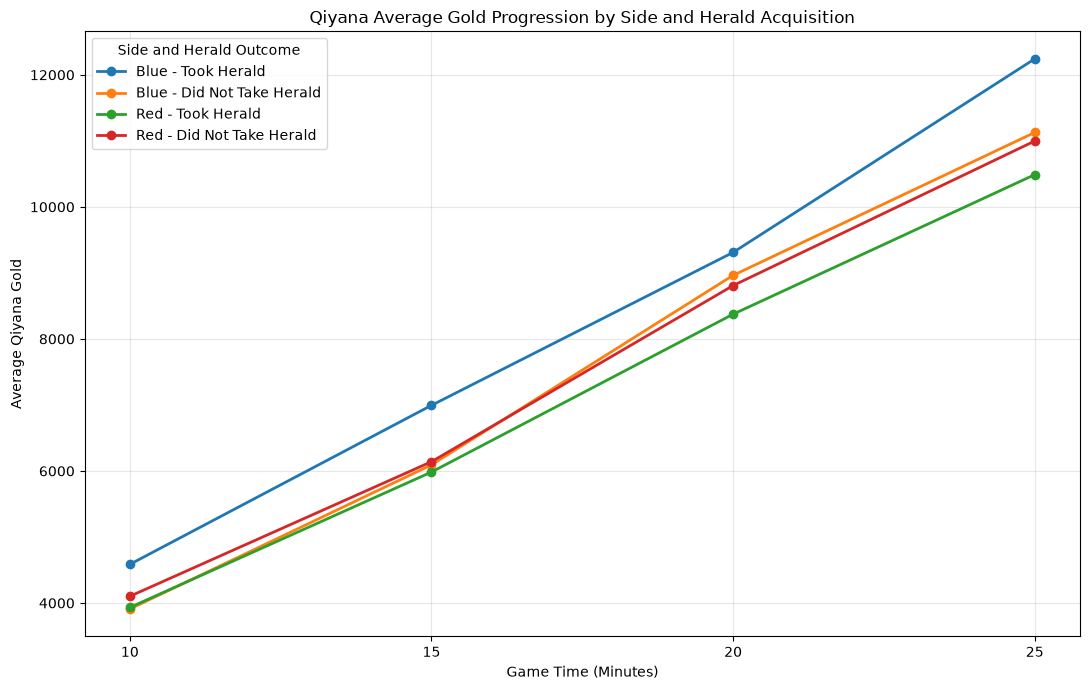

In [90]:
gold_columns = ["goldat10", "goldat15", "goldat20", "goldat25"]

qiyana_gold = qiyana_df.groupby("side_herald")[gold_columns].mean()

qiyana_gold.columns = [10, 15, 20, 25]

plt.figure(figsize=(11, 7))

for group in group_order:
    if group in qiyana_gold.index:
        plt.plot(
            qiyana_gold.columns,
            qiyana_gold.loc[group],
            marker="o",
            linewidth=2,
            label=group
        )

plt.title("Qiyana Average Gold Progression by Side and Herald Acquisition")
plt.xlabel("Game Time (Minutes)")
plt.ylabel("Average Qiyana Gold")
plt.xticks([10, 15, 20, 25])
plt.legend(title="Side and Herald Outcome")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [91]:
qiyana_summary = qiyana_df.groupby("side_herald").agg(
    games=("gameid", "nunique"),
    mean_xp10=("xpat10", "mean"),
    mean_xp15=("xpat15", "mean"),
    mean_xp20=("xpat20", "mean"),
    mean_xp25=("xpat25", "mean"),
    mean_gold10=("goldat10", "mean"),
    mean_gold15=("goldat15", "mean"),
    mean_gold20=("goldat20", "mean"),
    mean_gold25=("goldat25", "mean")
)

display(qiyana_summary.reindex(group_order).round(0))

,games,mean_xp10,mean_xp15,mean_xp20,mean_xp25,mean_gold10,mean_gold15,mean_gold20,mean_gold25
side_herald,,,,,,,,,
Blue - Took Herald,3,4587.0,8086.0,11228.0,14733.0,4586.0,6994.0,9311.0,12242.0
Blue - Did Not Take Herald,3,4212.0,6991.0,9929.0,12369.0,3910.0,6093.0,8963.0,11127.0
Red - Took Herald,3,4087.0,6691.0,9684.0,12352.0,3933.0,5984.0,8375.0,10488.0
Red - Did Not Take Herald,9,4424.0,6904.0,10190.0,12888.0,4102.0,6141.0,8808.0,10998.0


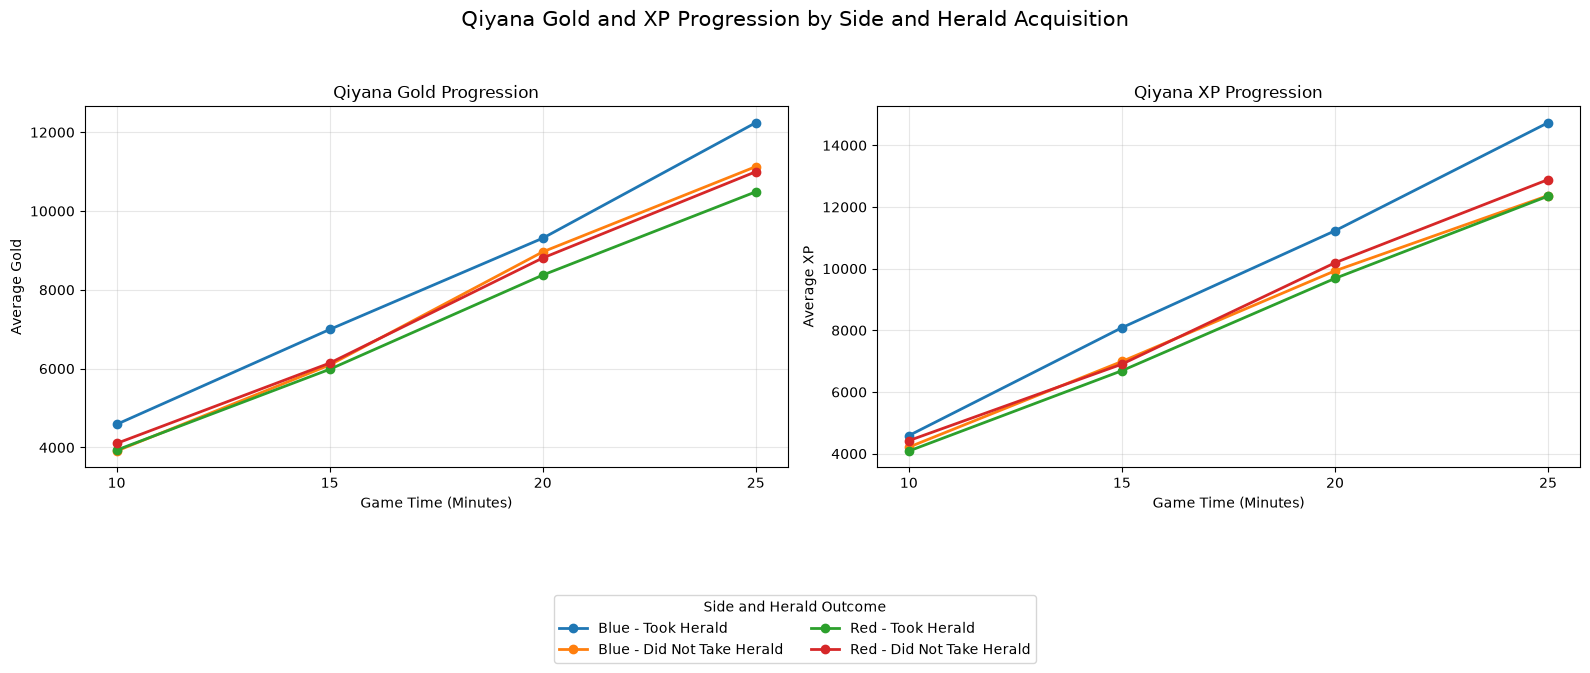

In [92]:
import matplotlib.pyplot as plt

# Define timestamps and comparison groups
gold_columns = ["goldat10", "goldat15", "goldat20", "goldat25"]
xp_columns = ["xpat10", "xpat15", "xpat20", "xpat25"]

group_order = [
    "Blue - Took Herald",
    "Blue - Did Not Take Herald",
    "Red - Took Herald",
    "Red - Did Not Take Herald"
]

# Calculate average progression for each group
qiyana_gold = qiyana_df.groupby("side_herald")[gold_columns].mean()
qiyana_xp = qiyana_df.groupby("side_herald")[xp_columns].mean()

# Replace column names with game minutes
qiyana_gold.columns = [10, 15, 20, 25]
qiyana_xp.columns = [10, 15, 20, 25]

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gold progression
for group in group_order:
    if group in qiyana_gold.index:
        axes[0].plot(
            qiyana_gold.columns,
            qiyana_gold.loc[group],
            marker="o",
            linewidth=2,
            label=group
        )

axes[0].set_title("Qiyana Gold Progression")
axes[0].set_xlabel("Game Time (Minutes)")
axes[0].set_ylabel("Average Gold")
axes[0].set_xticks([10, 15, 20, 25])
axes[0].grid(alpha=0.3)

# XP progression
for group in group_order:
    if group in qiyana_xp.index:
        axes[1].plot(
            qiyana_xp.columns,
            qiyana_xp.loc[group],
            marker="o",
            linewidth=2,
            label=group
        )

axes[1].set_title("Qiyana XP Progression")
axes[1].set_xlabel("Game Time (Minutes)")
axes[1].set_ylabel("Average XP")
axes[1].set_xticks([10, 15, 20, 25])
axes[1].grid(alpha=0.3)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Side and Herald Outcome",
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.12)
)

fig.suptitle(
    "Qiyana Gold and XP Progression by Side and Herald Acquisition",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.12, 1, 0.94])
plt.show()

In [93]:
#lets look at xp of all jgls

print(elixir_df["position"].value_counts())

position
top     144
jng     144
mid     144
bot     144
sup     144
team    144
Name: count, dtype: int64


In [94]:
jungle_df = elixir_df[
    elixir_df["position"] == "jng"
].copy()

print("Total jungle player observations:", len(jungle_df))
print("\nObservations by side:")
print(jungle_df["side"].value_counts())

Total jungle player observations: 144

Observations by side:
side
Blue    72
Red     72
Name: count, dtype: int64


,10,15,20,25
side,,,,
Blue,4156.0,6768.0,9430.0,12141.0
Red,4088.0,6504.0,9218.0,11754.0


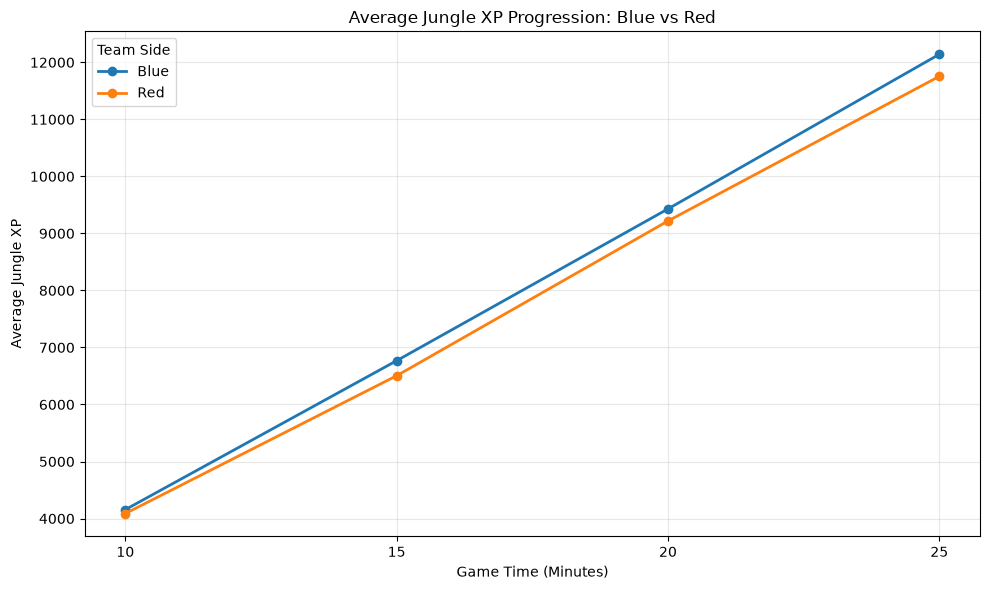

In [96]:
import matplotlib.pyplot as plt

# Filter jungle players
jungle_df = elixir_df[
    elixir_df["position"].isin(["jng", "jgl"])
].copy()

# XP columns
xp_columns = ["xpat10", "xpat15", "xpat20", "xpat25"]

# Calculate average XP by side
jungle_xp = jungle_df.groupby("side")[xp_columns].mean()

# Rename columns to game minutes
jungle_xp.columns = [10, 15, 20, 25]

# Display averages
display(jungle_xp.round(0))

# Plot Blue vs Red
plt.figure(figsize=(10, 6))

for side in ["Blue", "Red"]:
    if side in jungle_xp.index:
        plt.plot(
            jungle_xp.columns,
            jungle_xp.loc[side],
            marker="o",
            linewidth=2,
            label=side
        )

plt.title("Average Jungle XP Progression: Blue vs Red")
plt.xlabel("Game Time (Minutes)")
plt.ylabel("Average Jungle XP")
plt.xticks([10, 15, 20, 25])
plt.legend(title="Team Side")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [98]:
import pandas as pd
import matplotlib.pyplot as plt

# Keep only player rows (exclude team rows)
player_df = elixir_df[
    elixir_df["position"] != "team"
].copy()

# Check the available role labels
print(player_df["position"].value_counts())

position
top    144
jng    144
mid    144
bot    144
sup    144
Name: count, dtype: int64


In [99]:
# Map role abbreviations to readable names
role_names = {
    "top": "Top",
    "jng": "Jungle",
    "jgl": "Jungle",
    "mid": "Mid",
    "bot": "ADC",
    "sup": "Support"
}

player_df["role_name"] = player_df["position"].map(role_names)

# XP columns
xp_columns = ["xpat10", "xpat15", "xpat20", "xpat25"]

# Calculate average XP by role and side
role_xp = player_df.groupby(
    ["role_name", "side"]
)[xp_columns].mean()

display(role_xp.round(0))

xpat10  xpat15   xpat20   xpat25
role_name side                                  
ADC       Blue  3598.0  5979.0   8582.0  11289.0
          Red   3581.0  5946.0   8525.0  11016.0
Jungle    Blue  4156.0  6768.0   9430.0  12141.0
          Red   4088.0  6504.0   9218.0  11754.0
Mid       Blue  4979.0  7651.0  10311.0  13124.0
          Red   4972.0  7653.0  10202.0  13017.0
Support   Blue  2587.0  3738.0   5144.0   7027.0
          Red   2602.0  3759.0   5113.0   6760.0
Top       Blue  4959.0  8391.0  11481.0  14524.0
          Red   4986.0  8371.0  11485.0  14446.0

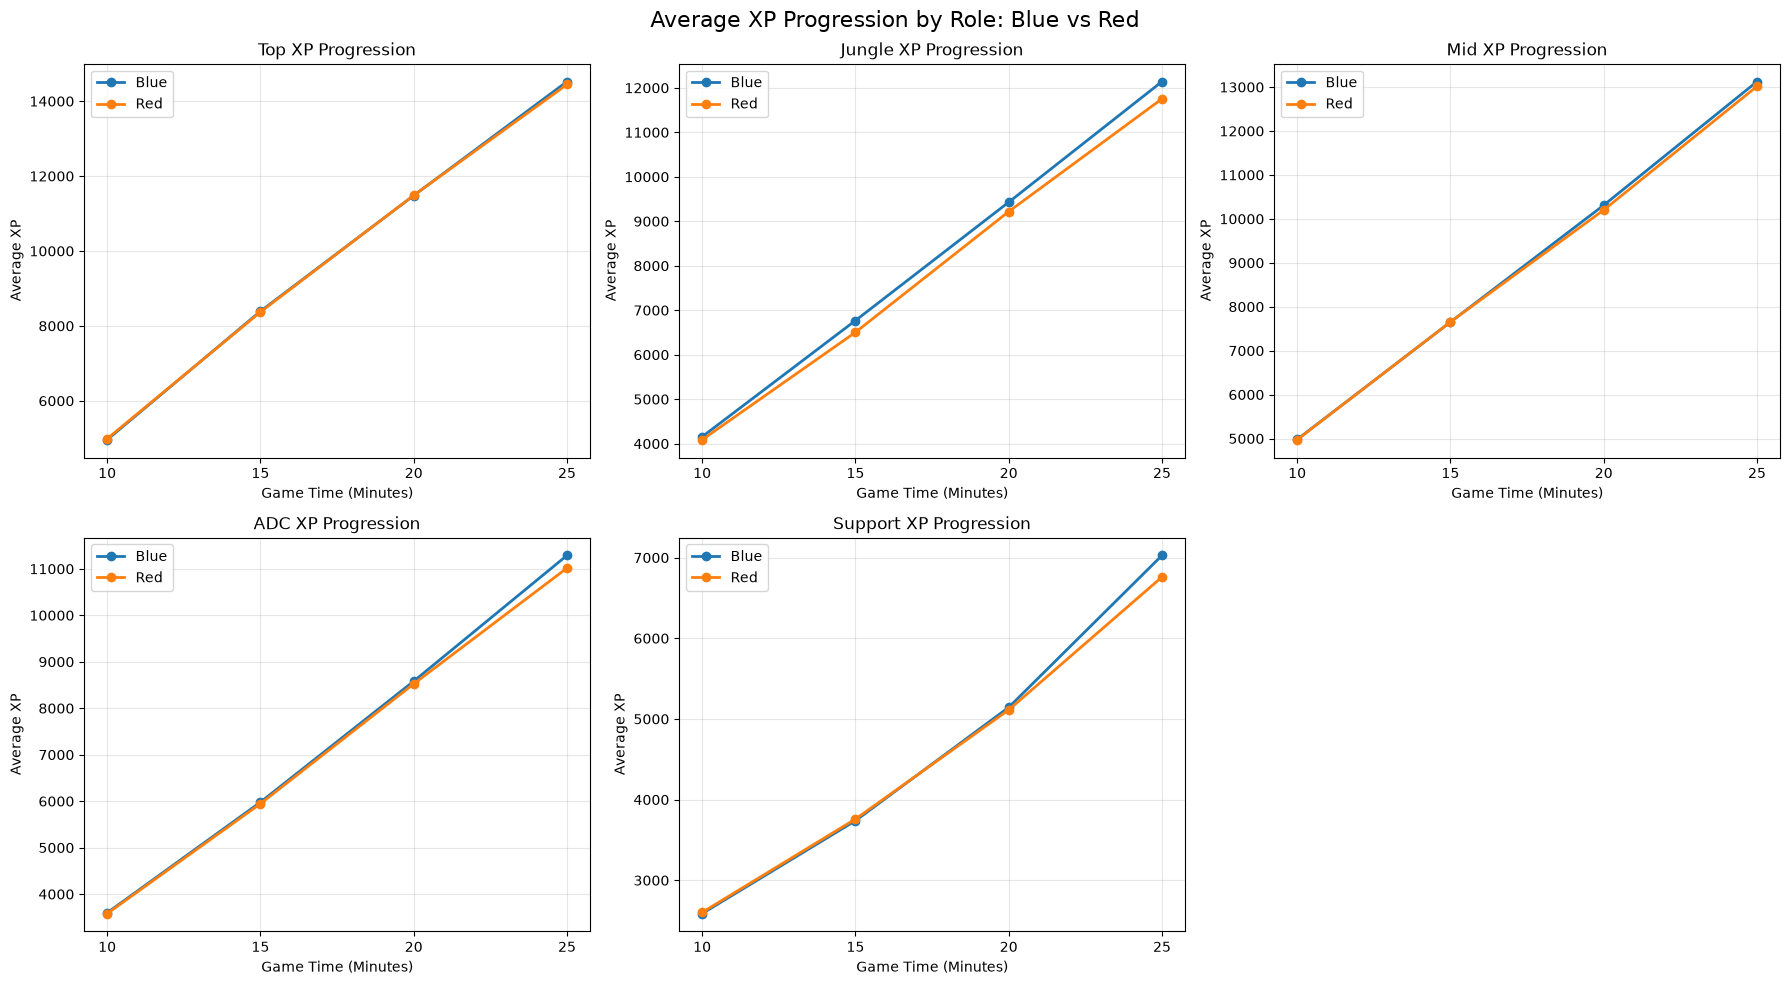

In [100]:
# Define role order and game times
roles = ["Top", "Jungle", "Mid", "ADC", "Support"]
game_times = [10, 15, 20, 25]

# Create a 2 x 3 grid
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, role in enumerate(roles):

    ax = axes[i]

    # Get XP averages for this role
    role_data = role_xp.loc[role].copy()

    # Rename columns to game minutes
    role_data.index = role_data.index
    role_data.columns = game_times

    # Plot Blue and Red
    for side in ["Blue", "Red"]:
        if side in role_data.index:
            ax.plot(
                game_times,
                role_data.loc[side],
                marker="o",
                linewidth=2,
                label=side
            )

    ax.set_title(f"{role} XP Progression")
    ax.set_xlabel("Game Time (Minutes)")
    ax.set_ylabel("Average XP")
    ax.set_xticks(game_times)
    ax.grid(alpha=0.3)
    ax.legend()

# Remove the unused sixth plot
fig.delaxes(axes[5])

fig.suptitle(
    "Average XP Progression by Role: Blue vs Red",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure role names are assigned
role_names = {
    "top": "Top",
    "jng": "Jungle",
    "jgl": "Jungle",
    "mid": "Mid",
    "bot": "ADC",
    "sup": "Support"
}

player_df["role_name"] = player_df["position"].map(role_names)

roles = ["Top", "Jungle", "Mid", "ADC", "Support"]
xp_columns = ["xpat10", "xpat15", "xpat20", "xpat25"]

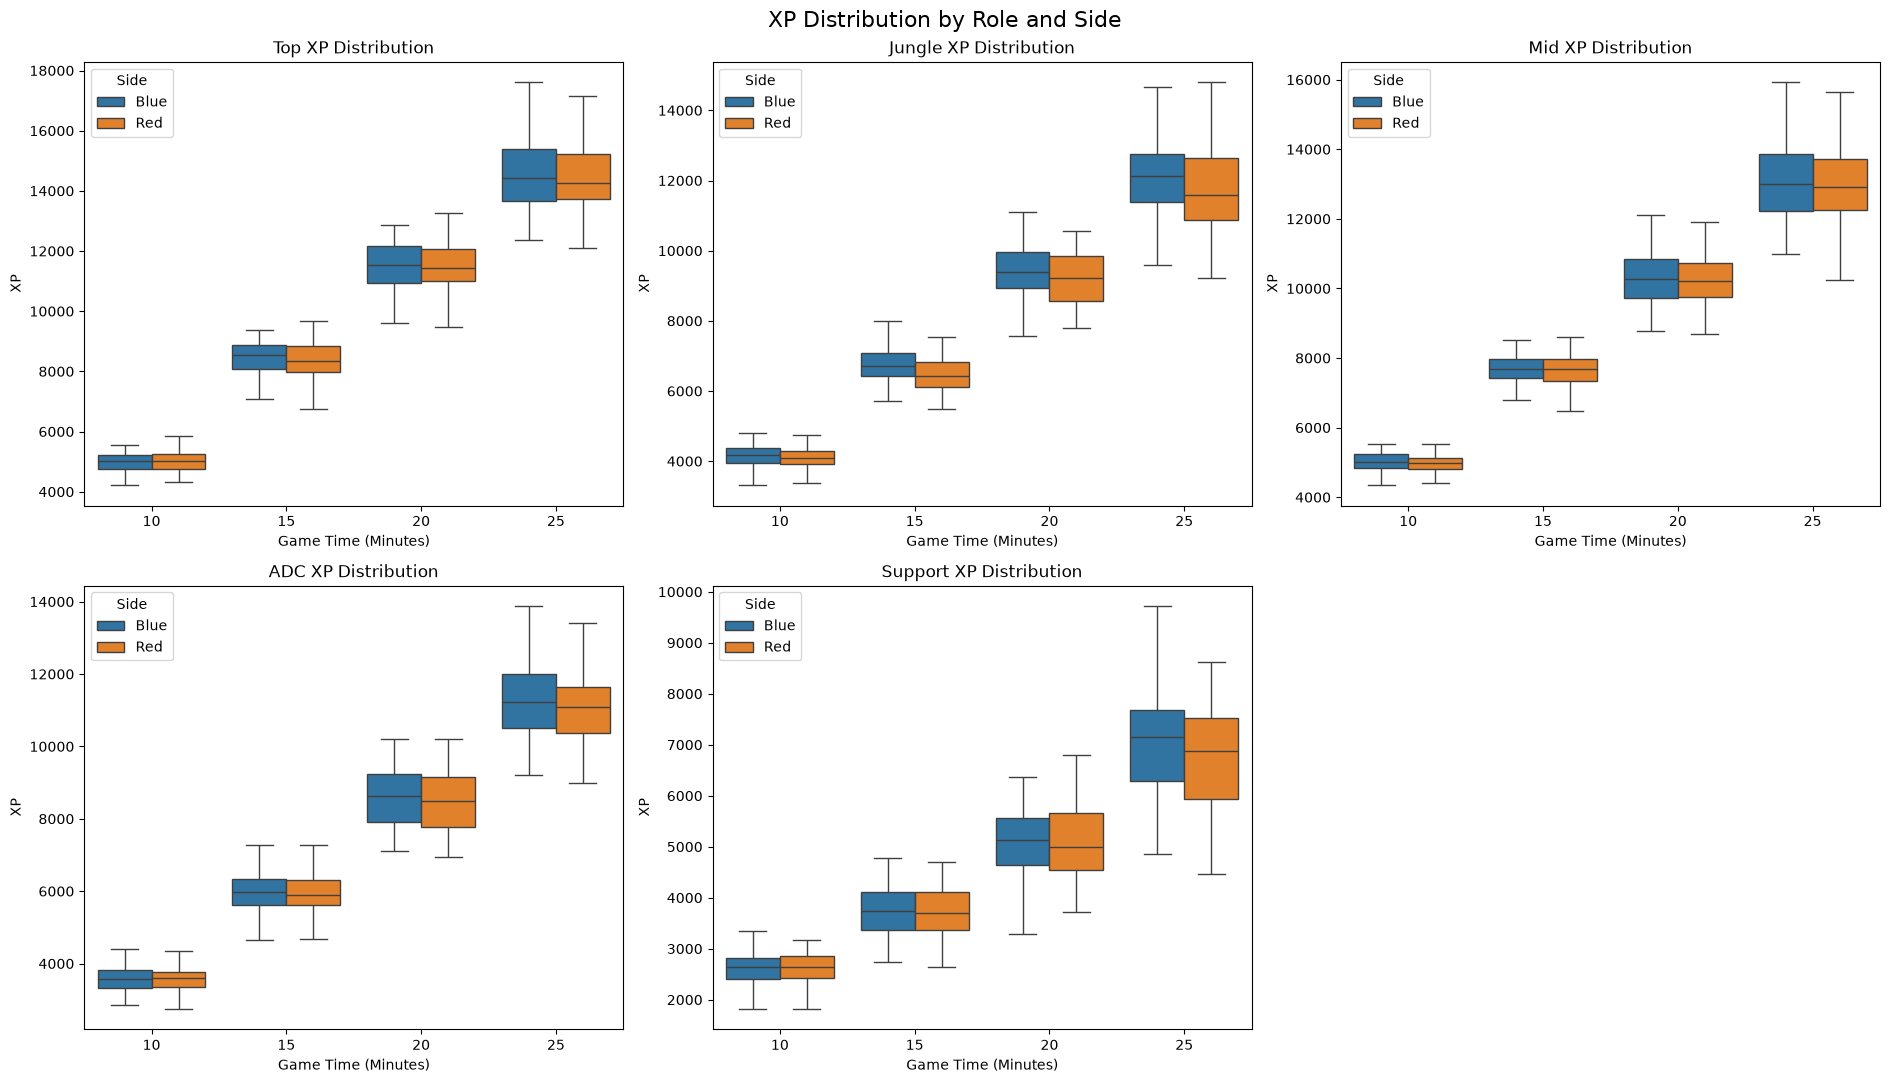

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
axes = axes.flatten()

for i, role in enumerate(roles):

    ax = axes[i]

    # Filter to the current role
    role_data = player_df[
        player_df["role_name"] == role
    ].copy()

    # Convert XP columns into a long format for seaborn
    role_long = role_data.melt(
        id_vars=["side"],
        value_vars=xp_columns,
        var_name="game_time",
        value_name="XP"
    )

    # Rename time labels
    role_long["game_time"] = role_long["game_time"].map({
        "xpat10": "10",
        "xpat15": "15",
        "xpat20": "20",
        "xpat25": "25"
    })

    sns.boxplot(
        data=role_long,
        x="game_time",
        y="XP",
        hue="side",
        order=["10", "15", "20", "25"],
        hue_order=["Blue", "Red"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{role} XP Distribution")
    ax.set_xlabel("Game Time (Minutes)")
    ax.set_ylabel("XP")
    ax.legend(title="Side")

# Remove unused sixth plot
fig.delaxes(axes[5])

fig.suptitle(
    "XP Distribution by Role and Side",
    fontsize=16
)

plt.tight_layout()
plt.show()